# What the prices were worth — calibration, longshot bias and the ladders

Three collectors went out to the venues and came back with a corpus: Polymarket's
72,838 settled political and macro markets, Kalshi's 100,233, PredictIt's live
snapshot, and the Iowa Electronic Markets back to June 1988. Their reports are
about **access** — what each venue serves, what it hides, and which of its fields
lie. This notebook asks the other question: **were the prices any good?**

It is worth saying what makes that question answerable here and not elsewhere.
A prediction market leaves behind the one thing a forecast almost never has — a
bounded price path that ends in a ground-truth label. So the accuracy of the
price is measurable rather than arguable, at every distance from the answer, and
that is what the five sections below do.

**The gap this is aimed at.** The published calibration literature stops at one
month. [Nam Anh Le](https://arxiv.org/abs/2602.19520) bins by time to resolution
in nine buckets and the longest is "1mo+"; Polymarket's own accuracy page
snapshots at one month, one week, one day, twelve hours and four hours and
publishes no sample size; the one peer-reviewed cross-venue study
(Clinton & Huang) covers the final five weeks of the 2024 election. For the one-
to-three-year horizon there is **no calibration evidence from any source**. The
corpus reaches 890 days, so the horizon buckets below run to two years, and the
answer at range turns out to be different from the answer at a month in a way
that matters for how a price is used.

**What this is not.** It is not a trading strategy and it is not an edge. Every
number here is measured on markets that have already settled, with fees ignored,
on daily prices that were not necessarily executable. It measures how far a price
sat from the truth, and nothing about whether the gap was reachable.

**The five sections.**

1. **One shape** — the three venues in one panel, and the register of everything
   that had to be forced to get them there. Two of the forcings change the
   answer and are measured rather than asserted.
2. **Calibration by horizon** — the reliability curve, Brier score and slope, cut
   by venue, by domain and above all by time to resolution. The composition
   worry that would explain the whole gradient away is tested and rejected.
3. **Longshot bias** — measured per venue rather than taken from the literature,
   and reported in two units because the two disagree.
4. **The ladders** — a row of "X by date T" markets as a cumulative distribution
   over the resolution date: monotonicity, interval hazards, negative mass, and
   whether coherence tracks liquidity.
5. **Which metrics matter** — the deliverable. Which of the quality measures in
   the catalogue actually separate a calibrated market from a miscalibrated one,
   ranked by how much they buy, with usable thresholds. Several of the most
   recommended ones do nothing, and one is worse than nothing.

Section 6 says what the whole thing supports and what it does not.

In [1]:
%reload_ext autoreload
%autoreload 2

import sys
from pathlib import Path

# Anchor on this notebook's own directory rather than on the working directory:
# VS Code can root a notebook at the workspace folder instead of at the file,
# and then a relative "../" resolves somewhere else and the imports below fail.
_here = Path.cwd()
_PM = _here if (_here / "utils" / "corpus.py").exists() else _here / "notebooks" / "prediction_markets"
for _path in (str(_PM), str(_PM.parents[1]), str(_PM.parents[2] / "navi")):
    if _path not in sys.path:
        sys.path.insert(0, _path)

import json
import textwrap

import numpy
from matplotlib import pyplot

from lib import config
from utils import corpus, metrics

pyplot.style.use(config.glyfish_style)

#: One colour per venue, held fixed across every figure here. Taken from the
#: house cycler rather than chosen, so these figures sit beside the others.
VENUE_COLOUR = {"polymarket": "#0067C4", "kalshi": "#FF9500", "iem": "#5600C9"}
VENUE_NAME = {"polymarket": "Polymarket", "kalshi": "Kalshi", "iem": "IEM"}


def stamp_source(*names: str, figure=None) -> None:
    """Name the files a figure was drawn from, along its bottom edge.

    Same helper as notebooks/fbi/utils/filing.py, restated here rather than
    imported: that one lives in the FBI notebook's own utils package and this
    notebook has no other reason to reach into it.
    """
    figure = figure or pyplot.gcf()
    figure.subplots_adjust(bottom=max(0.12, 0.09 + 0.030 * len(names)))
    figure.text(0.995, 0.005, "\n".join(names), ha="right", va="bottom",
                fontsize=7, family="monospace", alpha=0.65)


print(f"corpus files under {corpus.DATA}")
print(f"{len(metrics.VENUE_COVERAGE)} metric families in the catalogue, "
      f"{len(metrics.NOT_COMPUTABLE)} entries in NOT_COMPUTABLE")

corpus files under /Users/troy/Develop/gly.fish/meida/notebooks/prediction_markets/data
17 metric families in the catalogue, 9 entries in NOT_COMPUTABLE


## 1. One shape, and what had to be forced

The three venues do not disagree about field *names* — that is a rename and the
loaders handle it silently. They disagree about what a row **means**, and those
disagreements cannot be papered over, because two of them change the answer.
`corpus.FORCED` is the register: what each venue does, what was forced, and what
it costs. It is printed in full rather than summarised.

In [2]:
for name, (venues, forced, cost) in corpus.FORCED.items():
    print(f"\n{'-' * 78}\n{name.upper()}")
    for label, text in (("venues", venues), ("forced", forced), ("cost", cost)):
        wrapped = textwrap.fill(text, 74, initial_indent="  ", subsequent_indent="          ")
        print(f"  {label:7}{wrapped[2:]}")


------------------------------------------------------------------------------
PRICE
  venues Polymarket serves one forward-filled last trade per day at fidelity=1440
          and no quote on the path at all. Kalshi's daily candle carries
          yes_bid, yes_ask, mid, close and mean, and `close` is null on
          the 55% of market-days with no trade. IEM publishes
          low/high/last and no book at all except in its single 1988 file.
  forced Kalshi uses `mid` where present and falls back to `close`; Polymarket
          and IEM use the last trade, which is all they have.
  cost   The two large venues' prices are different objects: a quiet Polymarket
          day is a stale print, a quiet Kalshi day is a live quote. A
          stale print is the older belief and therefore the *worse*
          forecast of the two at the same horizon, which flatters Kalshi.
          kalshi_price_basis_sensitivity() measures the size of it.

------------------------------------------------

### What each venue actually contributes

The panel is one row per market-day, keyed to a market that carries a settled
binary outcome. Loading it is where three of the four venues lose most of their
corpus, and the attrition is the honest statement of how much labelled evidence
exists at all.

**PredictIt contributes nothing, and that is a finding rather than an omission.**
Its chart endpoint serves exactly seven days regardless of the `timespan`
parameter — twelve requests with eight different values returned twelve identical
payloads — and it silently truncates to a market's first six contracts, so an
eleven-rung ladder charts six rungs with no error. There is no reachable bulk
download. The recorder the PredictIt collector built accumulates history forward
from the day it starts; on 26 September 2026 it holds two snapshots. Nothing
before that is recoverable by code, so PredictIt cannot contribute a single
labelled observation to a calibration study today, however good its markets are.
That is the clearest illustration in this whole corpus of why the collectors ran
before the analysis: the venue most often cited as the *research* venue is the
one venue whose history cannot be had.

In [3]:
panel = corpus.load_panel(progress=lambda note: print(f"  {note} ...", flush=True))
census = panel.describe()

print(f"\n{len(panel.markets):,} markets, {len(panel):,} market-days, "
      f"longest horizon {census['max_horizon_days']:,.0f} days\n")
print(f"{'venue':12}{'markets':>10}{'market-days':>13}{'median life':>13}"
      f"{'base rate YES':>15}{'price basis':>18}")
for venue in ("polymarket", "kalshi", "iem"):
    picked = [m for m in panel.markets if m.venue == venue]
    if not picked:
        continue
    life = numpy.median([m.life_days for m in picked])
    yes = numpy.mean([m.outcome for m in picked])
    days = census["obs_by_venue"][venue]
    print(f"{VENUE_NAME[venue]:12}{len(picked):10,}{days:13,}{life:12.0f}d"
          f"{yes:14.1%} {picked[0].price_basis:>18}")
print(f"{'PredictIt':12}{0:>10}{0:>13}{'—':>13}{'—':>15}{'no history API':>18}")

# The attrition, venue by venue. Each figure is the collectors' own count from
# their manifests, so the loss at each step is attributable rather than implied.
print("\nWhat was lost getting here")
polymarket_manifest = json.loads((corpus.DATA / "polymarket_manifest.json").read_text())
kalshi_census = json.loads((corpus.DATA / "kalshi_census.json").read_text())
pm = [m for m in panel.markets if m.venue == "polymarket"]
ka = [m for m in panel.markets if m.venue == "kalshi"]
ie = [m for m in panel.markets if m.venue == "iem"]
print(f"  Polymarket {polymarket_manifest['markets']:>7,} harvested"
      f" -> {polymarket_manifest['price_paths']['markets_with_a_path']:>7,} with a stored path"
      f" -> {len(pm):>7,} also settled YES/NO with >=3 daily prints")
print(f"  Kalshi     {kalshi_census['settled']:>7,} settled"
      f" -> {4393:>7,} in the stratified candle pull"
      f" -> {len(ka):>7,} also settled yes/no (162 `scalar` rows excluded)")
print(f"  IEM        {89:>7,} resolved markets"
      f" -> {34:>7,} winner-take-all, terminal separation > 0.5"
      f" -> {len(ie):>7,} contract-level binary rows")

  loading polymarket ...


  loading kalshi ...


  loading iem ...



50,689 markets, 2,426,246 market-days, longest horizon 890 days

venue          markets  market-days  median life  base rate YES       price basis
Polymarket      46,223    1,646,552          12d         22.4%         last_trade
Kalshi           4,367      743,022         235d         27.5%     mid_else_close
IEM                 99       36,672         286d         27.3%         last_trade
PredictIt            0            0            —              —    no history API

What was lost getting here
  Polymarket  72,838 harvested ->  55,233 with a stored path ->  46,223 also settled YES/NO with >=3 daily prints
  Kalshi     100,233 settled ->   4,393 in the stratified candle pull ->   4,367 also settled yes/no (162 `scalar` rows excluded)
  IEM             89 resolved markets ->      34 winner-take-all, terminal separation > 0.5 ->      99 contract-level binary rows


### The two forcings that are not footnotes

**The price is a different object on the two large venues.** Polymarket serves
one forward-filled last trade per day and no quote at all; Kalshi's daily candle
carries bid, ask and mid, and its `close` is null on every day with no trade.
So a quiet Polymarket day reports an old print and a quiet Kalshi day reports a
live quote — and an old print is the *earlier* belief, which at the same nominal
horizon is the worse forecast. Left unmeasured, that asymmetry would flatter
Kalshi by construction.

It is measurable, because Kalshi serves both. The cell below loads Kalshi twice:
once reading the mid on every day, and once keeping only the days that traded.

In [4]:
sensitivity = corpus.kalshi_price_basis_sensitivity()

print(f"{'basis':16}{'market-days':>13}{'rows':>8}{'markets':>9}{'base':>8}"
      f"{'brier':>8}{'skill':>8}{'bias':>9}{'slope':>7}")
for basis, stats in sensitivity.items():
    print(f"{basis:16}{stats['market_days']:13,}{stats['n']:8,}{stats['n_markets']:9,}"
          f"{stats['base_rate']:8.3f}{stats['brier']:8.4f}{stats['skill']:+8.3f}"
          f"{stats['bias']:+9.4f}{stats['slope_linear']:7.3f}")

print(f"\n{'horizon':10}" + "".join(f"{b:>18}" for b in sensitivity))
for label in corpus.HORIZON_LABELS:
    cells = [sensitivity[b]["by_bucket"].get(label, {"n": 0}) for b in sensitivity]
    if min(c["n"] for c in cells) < 20:
        continue
    print(f"{label:10}" + "".join(
        f"{f'{c['n']:,} / {c['skill']:+.3f}':>18}" for c in cells))

traded = sensitivity["close_only"]["market_days"] / sensitivity["mid_else_close"]["market_days"]
print(f"\nOnly {traded:.1%} of Kalshi market-days carry a trade, so `close_only` "
      f"discards {1 - traded:.0%} of them.")

basis             market-days    rows  markets    base   brier   skill     bias  slope
mid_else_close        743,022  22,163    4,367   0.262  0.0718  +0.629  +0.0118  1.005
close_only            288,476  18,956    4,330   0.276  0.0739  +0.630  +0.0125  1.000

horizon       mid_else_close        close_only
<1d           3,560 / +0.861    2,574 / +0.834
1-7d          3,894 / +0.784    3,327 / +0.768
7-30d         4,081 / +0.704    3,767 / +0.693
30-90d        3,892 / +0.566    3,671 / +0.568
90-180d       3,088 / +0.469    2,785 / +0.470
180-365d      2,653 / +0.300    2,115 / +0.347
1-2y            990 / +0.118      713 / +0.158

Only 38.8% of Kalshi market-days carry a trade, so `close_only` discards 61% of them.


**Measured, the forcing is a footnote — and it is worth one sentence on why it
was checked anyway.** Reading the mid on every day against reading only the days
that traded leaves the pooled Brier skill at 0.629 against 0.630 and moves the
pooled bias by seven hundredths of a percentage point, on two samples that differ
by 61% of their market-days. The one place it does anything is at range: skill is
0.300 on mids against 0.347 on trades only at 180–365 days, and 0.118 against
0.158 at one to two years. Note which way that runs — restricting to days that
traded makes the venue look *better*, because it drops the markets that were not
being traded at all, which is a liquidity selection and not a price-basis effect.
**The mid is used throughout**, which is the conservative choice. Had this come
out the other way, every cross-venue number below would have inherited it.

**The second forcing cannot be measured away, only narrowed.** Polymarket's
stored paths cover 75.8% of its settled markets — near-population. Kalshi's cover
4,393 markets its collector selected for volume ≥ $500 and a non-intraday life —
a liquidity-stratified sample, which the collector said so plainly. A raw
venue-against-venue comparison therefore compares a liquid sample with a
population. `corpus.matched_stratum` applies Kalshi's rule to everything, which
does not make the samples the same but removes the part of the difference that is
known to be construction; it is applied wherever the two venues are put side by
side below, and the per-horizon comparison in section 2 is the one that matters
because it also holds the horizon mix fixed.

In [5]:
rows = corpus.market_bucket_rows(panel)
venue = panel.market_array("venue")[rows["m_index"]]
domain = panel.market_array("domain")[rows["m_index"]]
geo = panel.market_array("geo")[rows["m_index"]]
matched = corpus.matched_stratum(panel, rows)

print(f"market-days {len(panel):,} -> market-bucket rows {rows['price'].size:,} "
      f"({len(panel) / rows['price'].size:.1f}x inflation removed)\n")
print(f"{'horizon':10}{'markets':>9}{'rows':>8}" + "".join(
    f"{VENUE_NAME[v]:>12}" for v in ("polymarket", "kalshi", "iem")))
for bucket, label in enumerate(corpus.HORIZON_LABELS):
    picked = rows["bucket"] == bucket
    if not picked.any():
        continue
    counts = [int((picked & (venue == v)).sum()) for v in ("polymarket", "kalshi", "iem")]
    print(f"{label:10}{numpy.unique(rows['m_index'][picked]).size:9,}"
          f"{int(picked.sum()):8,}" + "".join(f"{c:12,}" for c in counts))
print(f"\nmatched stratum (volume >= $500, life >= 1 day) keeps "
      f"{matched.sum():,} of {matched.size:,} rows ({matched.mean():.1%})")

market-days 2,426,246 -> market-bucket rows 168,644 (14.4x inflation removed)

horizon     markets    rows  Polymarket      Kalshi         IEM
<1d          48,150  48,150      44,491       3,560          99
1-7d         50,062  50,062      46,069       3,894          99
7-30d        37,532  37,532      33,352       4,081          99
30-90d       18,720  18,720      14,738       3,892          90
90-180d       8,096   8,096       4,935       3,088          73
180-365d      4,957   4,957       2,231       2,653          73
1-2y          1,120   1,120          82         990          48
>2y               7       7           0           5           2

matched stratum (volume >= $500, life >= 1 day) keeps 155,172 of 168,644 rows (92.0%)


**The independence reduction is the largest single difference between the numbers
here and any that count market-days.** A market contributes one price per day for
its whole life, and consecutive days of one market are approximately the same
forecast; a 365-day market contributing 365 rows would be counted as 365
independent forecasts. So every headline number below is computed on **one
observation per market per horizon bucket** — the price nearest the geometric
centre of the bucket, which is a less arbitrary pick than "first" (biased to the
long end) or "last" (biased to the resolving move). That takes 2.4 million
market-days to 169 thousand rows, and it is why the sample sizes here are an
order of magnitude smaller than the ones the collectors reported.

The `>2y` bucket holds seven rows and is dropped from every table that follows.
It is not that nothing trades past two years — it is that nothing that traded
past two years has *settled* yet, which is the corpus's own horizon limit and
will relax on its own with time.

## 2. Calibration — the curve, the score, and the horizon

The reliability curve first, pooled across all three venues and all horizons: for
each band of price, the mean price in the band against the share that settled
YES. A calibrated market has the two equal.

In [6]:
print(f"{'band':8}{'rows':>9}{'mean price':>12}{'settled YES':>13}{'gap':>9}")
for row in corpus.reliability(rows["price"], rows["outcome"]):
    if not row["n"]:
        continue
    print(f"{row['band']:8}{row['n']:9,}{row['mean_price']:12.4f}"
          f"{row['realised']:13.4f}{row['gap']:+9.4f}")

pooled = corpus.brier(rows["price"], rows["outcome"])
pooled.update(corpus.calibration_slope(rows["price"], rows["outcome"]))
print(f"\npooled over {pooled['n']:,} rows: base rate {pooled['base_rate']:.4f}, "
      f"Brier {pooled['brier']:.4f} against a climatological {pooled['climatological']:.4f} "
      f"(skill {pooled['skill']:+.3f}), linear slope {pooled['slope_linear']:.3f}")

band         rows  mean price  settled YES      gap
<2c        68,713      0.0048       0.0025  +0.0023
2-5c       14,885      0.0327       0.0214  +0.0113
5-10c      12,125      0.0703       0.0573  +0.0130
10-25c     17,827      0.1647       0.1391  +0.0256
25-50c     21,948      0.3801       0.2904  +0.0897
50-75c     14,096      0.5943       0.5798  +0.0145
75-90c      6,254      0.8268       0.8487  -0.0219
>90c       12,796      0.9723       0.9843  -0.0119

pooled over 168,644 rows: base rate 0.2141, Brier 0.0725 against a climatological 0.1683 (skill +0.569), linear slope 0.995


Pooled, the corpus looks well behaved — a slope of 0.995 and a Brier skill of
0.57 over climatology. That number is close to useless on its own, because it
averages a four-hour forecast with a two-year one. Cutting by horizon is the
whole point, so here it is: the same statistics inside each bucket of time to
resolution, for all three venues at once and then for each separately.

Read the **bias** column — mean price minus realised rate, the amount by which
the price sat above the truth — and the **skill** column, which is the Brier
score against a constant forecast at that bucket's own base rate.

In [7]:
def horizon_table(mask, title, minimum=20):
    """Calibration statistics by horizon bucket, with the n on every line."""
    print(f"\n{title}")
    print(f"{'horizon':10}{'markets':>9}{'rows':>8}{'price':>8}{'realised':>10}"
          f"{'bias':>9}{'brier':>8}{'skill':>8}{'slope':>7}")
    for bucket, label in enumerate(corpus.HORIZON_LABELS):
        picked = mask & (rows["bucket"] == bucket)
        n = int(picked.sum())
        if n < minimum:
            print(f"{label:10}{numpy.unique(rows['m_index'][picked]).size:9,}{n:8,}"
                  f"{'   — too thin to read —':>42}")
            continue
        price, outcome = rows["price"][picked], rows["outcome"][picked]
        stats = corpus.brier(price, outcome)
        stats.update(corpus.calibration_slope(price, outcome))
        print(f"{label:10}{numpy.unique(rows['m_index'][picked]).size:9,}{n:8,}"
              f"{price.mean():8.3f}{stats['base_rate']:10.3f}"
              f"{price.mean() - stats['base_rate']:+9.4f}{stats['brier']:8.4f}"
              f"{stats['skill']:+8.3f}{stats['slope_linear']:7.3f}")


horizon_table(numpy.ones(rows["price"].size, dtype=bool), "All three venues")
for name in ("polymarket", "kalshi", "iem"):
    horizon_table(venue == name, VENUE_NAME[name])


All three venues
horizon     markets    rows   price  realised     bias   brier   skill  slope
<1d          48,150  48,150   0.226     0.230  -0.0039  0.0414  +0.767  1.033
1-7d         50,062  50,062   0.228     0.229  -0.0006  0.0739  +0.581  1.025
7-30d        37,532  37,532   0.226     0.197  +0.0296  0.0876  +0.446  0.953
30-90d       18,720  18,720   0.243     0.188  +0.0559  0.0957  +0.372  0.897
90-180d       8,096   8,096   0.232     0.186  +0.0461  0.0906  +0.401  0.945
180-365d      4,957   4,957   0.278     0.195  +0.0827  0.1182  +0.248  0.852
1-2y          1,120   1,120   0.265     0.175  +0.0896  0.1291  +0.106  0.726
>2y               7       7                      — too thin to read —

Polymarket
horizon     markets    rows   price  realised     bias   brier   skill  slope
<1d          44,491  44,491   0.221     0.226  -0.0042  0.0425  +0.757  1.034
1-7d         46,069  46,069   0.223     0.224  -0.0005  0.0765  +0.560  1.026
7-30d        33,352  33,352   0.220     0.

**Three venues, three eras, one shape.** Inside a week every venue is calibrated
to within a fifth of a percentage point. From a month out the price begins to sit
above the truth, and by one to two years it sits **9.0 points above** it pooled —
Polymarket +14.6, Kalshi +9.4, IEM −10.4. Brier skill falls monotonically from
0.77 to 0.11: at one to two years a market price is barely better than knowing
the base rate. The linear slope falls from 1.03 to 0.73, which is the price
moving *more* than the truth does.

That is the published one-month result extended by a factor of twenty-four, and
extended is the right word: the shape at a month is the shape the literature
reports, and it keeps going.

**IEM points the other way at range, and it is the most interesting single line
in the table.** Its bias is −5.4 points at six months to a year and −10.4 at one
to two years — the price *below* the truth, where both modern venues are above
it. IEM is also the only venue here with **no trading commission** (accounts cap
at $500, one $5 set-up fee), against Polymarket's 4% taker fee on politics and
Kalshi's quadratic schedule. That is a consistent story and it is not a test: the
IEM cells hold 48 to 73 contract-rows drawn from a handful of election years, the
bootstrap interval below barely excludes zero, and the composition is completely
different from either modern venue's. Treat it as the one observation that a
fee-free venue behaves differently at range, worth a designed test and not worth
a conclusion.

### The objection that would explain all of this away

A market only contributes a one-to-two-year observation if it *lived* one to two
years. So the long buckets are made of long-lived markets, which are different
questions from the short-lived ones — and the whole gradient could be
composition rather than horizon. The base rates in the table move with the
bucket, which is exactly what that objection predicts.

The test is to hold the markets fixed: restrict to markets that lived at least
365 days, so that **the same markets appear in every bucket**, and let each one
be scored against its own outcome at every distance. The realised column then
cannot move except through rows dropping out, and any remaining gradient is the
same markets being wrong differently at different distances.

In [8]:
life = panel.market_array("life_days")[rows["m_index"]].astype(float)

for name in ("polymarket", "kalshi", "iem"):
    picked = (venue == name) & (life >= 365)
    held = numpy.unique(rows["m_index"][picked]).size
    print(f"\n{VENUE_NAME[name]} — the {held:,} markets that lived at least 365 days")
    print(f"{'horizon':10}{'rows':>7}{'price':>8}{'realised':>10}{'bias':>9}"
          f"{'brier':>8}{'skill':>8}")
    for bucket, label in enumerate(corpus.HORIZON_LABELS):
        cell = picked & (rows["bucket"] == bucket)
        if cell.sum() < 20:
            continue
        price, outcome = rows["price"][cell], rows["outcome"][cell]
        stats = corpus.brier(price, outcome)
        print(f"{label:10}{stats['n']:7,}{price.mean():8.3f}{stats['base_rate']:10.3f}"
              f"{price.mean() - stats['base_rate']:+9.4f}{stats['brier']:8.4f}"
              f"{stats['skill']:+8.3f}")


Polymarket — the 96 markets that lived at least 365 days
horizon      rows   price  realised     bias   brier   skill
<1d            92   0.089     0.076  +0.0131  0.0055  +0.921
1-7d           96   0.094     0.083  +0.0110  0.0077  +0.899
7-30d          96   0.111     0.083  +0.0274  0.0138  +0.820
30-90d         96   0.114     0.083  +0.0305  0.0322  +0.579
90-180d        95   0.144     0.084  +0.0601  0.0438  +0.431
180-365d       89   0.163     0.090  +0.0729  0.0604  +0.261
1-2y           82   0.232     0.085  +0.1463  0.0977  -0.252

Kalshi — the 990 markets that lived at least 365 days
horizon      rows   price  realised     bias   brier   skill
<1d           755   0.193     0.192  +0.0010  0.0110  +0.929
1-7d          846   0.188     0.187  +0.0017  0.0133  +0.913
7-30d         913   0.182     0.182  +0.0001  0.0168  +0.887
30-90d        961   0.197     0.180  +0.0167  0.0319  +0.784
90-180d       969   0.196     0.180  +0.0164  0.0455  +0.691
180-365d      989   0.203     0.1

**The objection does not survive, and the way it fails is clean.** On the 990
Kalshi markets that lived over a year the realised rate is 0.177 in *every*
bucket — by construction, since it is the same 990 outcomes — while the mean
price climbs from 0.193 inside a day to 0.271 at one to two years. The same
holds on Polymarket's 96 (realised 0.076–0.090 throughout, price 0.089 → 0.232)
and on IEM's 48 (realised 0.292 throughout, price 0.291 → 0.188, the other way).

So the gradient is not a change of population. **It is the same markets, on the
same questions, whose prices were further from their own eventual answers the
further out you look — and further in a consistent direction.** On a fixed
96-market Polymarket sample the bias rises 13.3 points from end to end (+1.31 to
+14.63) against 15.0 in the unrestricted table where the sample changes at every
bucket; on a fixed 990-market Kalshi sample it rises 9.3 points (+0.10 to +9.43)
against 9.5. The gradient survives the test essentially intact, which is the
result the test was built to get.

Note also what the held-fixed panels are *not*. Their levels sit lower than the
pooled ones at intermediate horizons — Polymarket's long-lived markets are cheap,
with a realised rate of 0.083 against 0.186 pooled at a month — so this is a
sharper identification, not a larger effect.

**One distinction the panel forces, and it is the most useful thing in this
section.** Brier skill decays on all three venues — Kalshi 0.929 → 0.118, IEM
1.000 → 0.044. Bias grows on two of them and not on the third. Those are
different statements and they are usually collapsed into "long-horizon markets
are badly calibrated":

- **Skill decay is not a defect.** A market a year out knows less than a market a
  day out because the world has not happened yet. Nothing can be done about it
  and no venue is at fault.
- **Bias growth is a pricing defect**, because it is directional and therefore
  correctable — a market that is +9 points high at a year can be corrected by
  subtracting nine points, and one that is merely uninformative cannot be
  corrected at all.

IEM separates them: flat bias out to a year while its skill decays from 1.00 to
0.21. That is what "loses information without becoming wrong" looks like, and it
is the only place in this corpus where the two come apart.

In [9]:
# Every interval below resamples MARKETS, not rows: rows from one market are not
# independent, and resampling rows would give an interval several times too
# narrow. It is still not exact -- one market's rows across buckets are
# correlated with each other -- but it puts the clustering in the right place.
def bias(price, outcome):
    return float(numpy.mean(price) - numpy.mean(outcome))


print(f"{'venue':12}{'horizon':10}{'rows':>7}{'bias':>9}{'95% interval':>22}  verdict")
for name in ("polymarket", "kalshi", "iem"):
    for bucket in (2, 3, 4, 5, 6):
        cell = (venue == name) & (rows["bucket"] == bucket)
        if cell.sum() < 40:
            continue
        price, outcome = rows["price"][cell], rows["outcome"][cell]
        lo, hi = corpus.bootstrap_ci(price, outcome, rows["m_index"][cell], bias, draws=400)
        point = bias(price, outcome)
        verdict = "excludes zero" if (lo > 0 or hi < 0) else "includes zero"
        print(f"{VENUE_NAME[name]:12}{corpus.HORIZON_LABELS[bucket]:10}{int(cell.sum()):7,}"
              f"{point:+9.4f}{f'[{lo:+.4f}, {hi:+.4f}]':>22}  {verdict}")

venue       horizon      rows     bias          95% interval  verdict


Polymarket  7-30d      33,352  +0.0337    [+0.0304, +0.0369]  excludes zero


Polymarket  30-90d     14,738  +0.0703    [+0.0656, +0.0755]  excludes zero


Polymarket  90-180d     4,935  +0.0673    [+0.0598, +0.0746]  excludes zero
Polymarket  180-365d    2,231  +0.1226    [+0.1090, +0.1348]  excludes zero
Polymarket  1-2y           82  +0.1463    [+0.0875, +0.2027]  excludes zero


Kalshi      7-30d       4,081  -0.0034    [-0.0103, +0.0041]  includes zero
Kalshi      30-90d      3,892  +0.0029    [-0.0066, +0.0107]  includes zero


Kalshi      90-180d     3,088  +0.0134    [+0.0026, +0.0246]  excludes zero
Kalshi      180-365d    2,653  +0.0528    [+0.0397, +0.0664]  excludes zero
Kalshi      1-2y          990  +0.0943    [+0.0755, +0.1187]  excludes zero
IEM         7-30d          99  -0.0009    [-0.0524, +0.0558]  includes zero
IEM         30-90d         90  -0.0100    [-0.0766, +0.0530]  includes zero
IEM         90-180d        73  -0.0001    [-0.0809, +0.0746]  includes zero
IEM         180-365d       73  -0.0545    [-0.1532, +0.0319]  includes zero


IEM         1-2y           48  -0.1036    [-0.2225, -0.0027]  excludes zero


Polymarket's overpricing excludes zero at every horizon from a week out. Kalshi's
does from three months out and not before — inside three months its bias interval
straddles zero, which is the strongest thing in this notebook in Kalshi's favour.
IEM's one-to-two-year interval is `[-0.221, -0.003]`: it excludes zero by three
tenths of a percentage point on 48 rows, which is exactly the kind of result that
should be reported and not leaned on.

Now the picture. Two panels: the bias against horizon on the left, and Brier
skill on the right, with the pooled line and the held-fixed long-lived subset
drawn together so the composition test is visible rather than described.

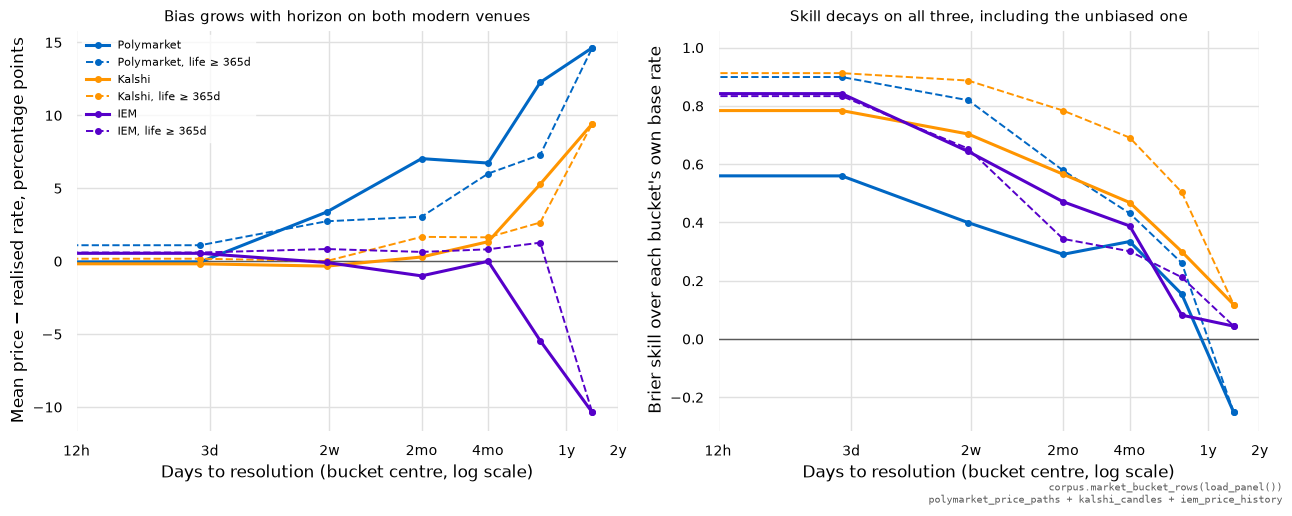

In [10]:
figure, (left, right) = pyplot.subplots(1, 2, figsize=(13, 5.2))
centres = numpy.sqrt(numpy.asarray(corpus.HORIZON_EDGES[:-2])
                     * numpy.asarray(corpus.HORIZON_EDGES[1:-1]))

for name in ("polymarket", "kalshi", "iem"):
    for restricted, style, width, tag in ((False, "-", 2.2, ""), (True, "--", 1.4, ", life ≥ 365d")):
        picked = (venue == name) & ((life >= 365) if restricted else True)
        xs, biases, skills = [], [], []
        for bucket in range(len(corpus.HORIZON_LABELS) - 1):
            cell = picked & (rows["bucket"] == bucket)
            if cell.sum() < 40:
                continue
            price, outcome = rows["price"][cell], rows["outcome"][cell]
            xs.append(centres[bucket])
            biases.append(100.0 * (price.mean() - outcome.mean()))
            skills.append(corpus.brier(price, outcome)["skill"])
        if len(xs) < 3:
            continue
        label = VENUE_NAME[name] + tag
        left.plot(xs, biases, style, color=VENUE_COLOUR[name], lw=width,
                  marker="o", ms=4, label=label)
        right.plot(xs, skills, style, color=VENUE_COLOUR[name], lw=width, marker="o", ms=4)

left.axhline(0.0, color="0.35", lw=1.0, zorder=1)
left.set_ylabel("Mean price − realised rate, percentage points")
left.set_title("Bias grows with horizon on both modern venues", fontsize=11)
left.legend(loc="upper left", fontsize=8)
right.axhline(0.0, color="0.35", lw=1.0, zorder=1)
right.set_ylabel("Brier skill over each bucket's own base rate")
right.set_title("Skill decays on all three, including the unbiased one", fontsize=11)
for axis in (left, right):
    axis.set_xscale("log")
    axis.set_xlabel("Days to resolution (bucket centre, log scale)")
    axis.set_xticks([0.5, 3, 15, 52, 127, 365, 730])
    axis.set_xticklabels(["12h", "3d", "2w", "2mo", "4mo", "1y", "2y"])
figure.tight_layout()
stamp_source("corpus.market_bucket_rows(load_panel())",
             "polymarket_price_paths + kalshi_candles + iem_price_history")
pyplot.show()

The dashed lines are the held-fixed subsets. On the left panel they trace the same
monotone rise as the solid ones and converge onto them at the right-hand end,
where the two samples become the same markets by construction. They sit *lower*
in the middle — a long-lived market is a cheaper market — which is why the panel
is worth drawing: the effect is not an artefact of the pooled sample's changing
composition, and it is also not made bigger by removing it.

The right panel is the one that carries the distinction drawn above. Every line
falls, dashed and solid, on all three venues. The purple pair falls as steeply as
any while the purple line on the left stays flat until the last point. That is
information loss without directional error, and it is what a venue looks like when
it stops knowing rather than starting to lie.

### By domain, and one cut the corpus cannot do cleanly

The user's two categories are political and financial/macro. Kalshi labels every
series; Polymarket has no category at all, so `domain` there is built from the
collectors' curated tag registry, with the `geopolitics` tag kept as its own
sub-cut. These are **not the same populations across venues** — Kalshi's
Financials is mostly dead index-strike ladder rungs (41% never traded, median
volume $23, per its collector), while Polymarket's financial tags are oil, the
Fed and trade-war headlines. Compare a domain within a venue; do not compare
"macro" across venues.

In [11]:
print(f"{'venue':12}{'domain':14}{'markets':>9}{'rows':>8}{'base':>8}{'brier':>8}"
      f"{'skill':>8}{'bias':>9}")
for name in ("polymarket", "kalshi"):
    cuts = [("political", (venue == name) & (domain == "political")),
            ("macro", (venue == name) & (domain == "macro"))]
    if name == "polymarket":
        cuts.append(("· geopolitics", (venue == name) & geo))
    for label, cell in cuts:
        if cell.sum() < 100:
            continue
        price, outcome = rows["price"][cell], rows["outcome"][cell]
        stats = corpus.brier(price, outcome)
        print(f"{VENUE_NAME[name]:12}{label:14}"
              f"{numpy.unique(rows['m_index'][cell]).size:9,}{stats['n']:8,}"
              f"{stats['base_rate']:8.3f}{stats['brier']:8.4f}{stats['skill']:+8.3f}"
              f"{price.mean() - stats['base_rate']:+9.4f}")

print("\nAnd the same cut at 180 days and beyond, where the bias lives")
print(f"{'venue':12}{'domain':14}{'rows':>8}{'base':>8}{'skill':>8}{'bias':>9}")
far = rows["bucket"] >= 5
for name in ("polymarket", "kalshi"):
    cuts = [("political", (venue == name) & (domain == "political") & far),
            ("macro", (venue == name) & (domain == "macro") & far)]
    if name == "polymarket":
        cuts.append(("· geopolitics", (venue == name) & geo & far))
    for label, cell in cuts:
        if cell.sum() < 60:
            print(f"{VENUE_NAME[name]:12}{label:14}{int(cell.sum()):8,}"
                  f"{'   — too thin —':>26}")
            continue
        price, outcome = rows["price"][cell], rows["outcome"][cell]
        stats = corpus.brier(price, outcome)
        print(f"{VENUE_NAME[name]:12}{label:14}{stats['n']:8,}{stats['base_rate']:8.3f}"
              f"{stats['skill']:+8.3f}{price.mean() - stats['base_rate']:+9.4f}")

venue       domain          markets    rows    base   brier   skill     bias
Polymarket  political        37,859 118,292   0.203  0.0705  +0.565  +0.0160
Polymarket  macro             8,364  27,606   0.220  0.0814  +0.526  +0.0245
Polymarket  · geopolitics     6,149  19,453   0.238  0.0797  +0.560  -0.0080
Kalshi      political         2,742  13,675   0.222  0.0616  +0.643  +0.0078
Kalshi      macro             1,625   8,488   0.327  0.0883  +0.599  +0.0182

And the same cut at 180 days and beyond, where the bias lives
venue       domain            rows    base   skill     bias
Polymarket  political        1,985   0.159  +0.181  +0.1214
Polymarket  macro              328   0.110  -0.159  +0.1357
Polymarket  · geopolitics      205   0.107  -0.087  +0.1400
Kalshi      political        2,043   0.160  +0.187  +0.0674
Kalshi      macro            1,605   0.283  +0.291  +0.0600


Pooled over all horizons the domains are close, and the interesting split is
where it always is — at range. Nothing here separates political from macro by
enough to act on once the horizon is held fixed, and the honest reading is that
**horizon dominates domain by a wide margin on both venues**. If a category cut
is wanted for sector work, it will have to come from somewhere other than
calibration, because calibration does not distinguish them.

## 3. Longshot bias, measured rather than assumed

The favourite-longshot bias is the best-known regularity in this literature and
the figure usually quoted for Polymarket is that purchases below 10¢ **lose 19.3¢
per dollar**. That number is a *return*, and the notebook reports two columns
because they do not agree about where the problem is:

- **`gap`** — mean price minus realised rate, in cents. The absolute
  miscalibration, and the number to apply as a correction.
- **`per $`** — `(realised − price) / price`, the return on a dollar staked at
  the band's mean price. This is the unit the literature quotes. At low prices it
  is a ratio of two small numbers, dominated by the band edge, and it is not a
  robust summary of anything.

In [12]:
def longshot(mask, title, minimum=60):
    print(f"\n{title}")
    print(f"{'band':8}{'rows':>9}{'mean price':>12}{'settled YES':>13}"
          f"{'gap, ¢':>9}{'per $, ¢':>10}")
    for row in corpus.longshot_table(rows["price"][mask], rows["outcome"][mask]):
        if row["n"] < minimum:
            continue
        print(f"{row['band']:8}{row['n']:9,}{row['mean_price']:12.4f}"
              f"{row['realised']:13.4f}{row['gap_cents']:+9.2f}{row['per_dollar']:+10.1f}")


for name in ("polymarket", "kalshi", "iem"):
    longshot(venue == name, VENUE_NAME[name], minimum=30 if name == "iem" else 60)


Polymarket
band         rows  mean price  settled YES   gap, ¢  per $, ¢
<2c        60,624      0.0044       0.0021    +0.23     -51.9
2-5c       12,603      0.0326       0.0213    +1.13     -34.6
5-10c      10,194      0.0704       0.0566    +1.38     -19.6
10-25c     15,391      0.1653       0.1390    +2.63     -15.9
25-50c     19,733      0.3805       0.2884    +9.21     -24.2
50-75c     12,109      0.5945       0.5775    +1.70      -2.9
75-90c      5,142      0.8261       0.8565    -3.04      +3.7
>90c       10,102      0.9725       0.9846    -1.21      +1.2

Kalshi
band         rows  mean price  settled YES   gap, ¢  per $, ¢
<2c         7,838      0.0077       0.0036    +0.41     -53.4
2-5c        2,258      0.0329       0.0217    +1.12     -34.0
5-10c       1,900      0.0697       0.0611    +0.87     -12.5
10-25c      2,355      0.1606       0.1397    +2.09     -13.0
25-50c      2,148      0.3780       0.3110    +6.70     -17.7
50-75c      1,942      0.5922       0.5906    +0.1

**The two columns tell different stories and the absolute one is the honest one.**
Below 2¢ the per-dollar figure reads −52¢ on Polymarket and −53¢ on Kalshi, which
sounds catastrophic; the absolute gap in the same cell is **+0.23¢ and +0.41¢**.
A contract priced at 0.4¢ that settles YES 0.2% of the time is very nearly right
in the only unit that matters for reading a price as a probability. The per-dollar
number is large because the denominator is small, and it is a statement about
*staking*, not about calibration.

**In absolute terms the worst-priced region is not the tail — it is the middle,
and the pattern reproduces on both venues independently.** Polymarket's largest
gap is **+9.21¢ in the 25–50¢ band** and Kalshi's is **+6.70¢ in the same band**;
both are three to eight times the gap anywhere below 10¢. Favourites are priced
about right or slightly cheap (Polymarket −3.04¢ at 75–90¢, −1.21¢ above 90¢;
Kalshi −1.13¢ above 90¢).

That is worth stating plainly because it inverts the usual advice. **The
correction a reader should carry is not mainly a longshot haircut — it is a
mid-range haircut**, of roughly seven to nine cents on a quarter-to-half-dollar
political contract, and a small one below a dime. The reference doc's
prescription of "a longshot haircut below ~10¢ (≈ ×0.8)" is defensible as a
return correction and misleading as a probability correction: ×0.8 on a 5¢ quote
moves it a penny, while the 25–50¢ band needs nine.

Three caveats. The 25–50¢ band is where the outcome variance is highest, so it is
also where a gap is hardest to pin down — though the direction agrees across two
venues with independent samples, which is what makes it worth saying. IEM's bands
hold 31 to 81 rows each and cannot carry any of this; its 25–50¢ cell reads
+12.96¢ in the same direction, on 67 rows, which is agreement and not evidence.

And IEM's sub-2¢ row is worth pausing on as an object lesson in the unit. It
reads a gap of **−5.74¢** and a per-dollar figure of **+2,473¢** — a 0.2¢ mean
price against a 6.0% realised rate, on 251 contract-rows. Those are IEM
per-candidate contracts quoted at the minimum tick that went on to win, and the
per-dollar column turns them into a number four orders of magnitude larger than
anything else in the table. Nothing is wrong with the arithmetic; the unit simply
stops meaning anything as the denominator goes to zero, which is the whole reason
both columns are printed.

### Does the bias live in the price band or in the horizon?

The two are tangled: long-dated markets are cheaper on average, and cheap markets
are longshots. Splitting the table both ways is the only way to see which one is
carrying the effect.

In [13]:
print(f"{'venue':12}{'band':8}" + "".join(
    f"{corpus.HORIZON_LABELS[b]:>12}" for b in (0, 2, 4, 5, 6)))
for name in ("polymarket", "kalshi"):
    for lo, hi, label in corpus.PRICE_BANDS:
        line, any_cell = f"{VENUE_NAME[name]:12}{label:8}", False
        for bucket in (0, 2, 4, 5, 6):
            cell = ((venue == name) & (rows["bucket"] == bucket)
                    & (rows["price"] >= lo) & (rows["price"] < hi))
            if cell.sum() < 60:
                line += f"{'—':>12}"
                continue
            any_cell = True
            gap = 100.0 * (rows["price"][cell].mean() - rows["outcome"][cell].mean())
            line += f"{f'{gap:+.2f}':>12}"
        if any_cell:
            print(line)
    print()

venue       band             <1d       7-30d     90-180d    180-365d        1-2y
Polymarket  <2c            +0.21       +0.22       +0.11       +0.59           —
Polymarket  2-5c           +1.40       +0.86       +2.27       +1.79           —
Polymarket  5-10c          +0.96       +0.72       +4.59       +3.47           —
Polymarket  10-25c         +0.77       +3.08       +5.91      +11.14           —
Polymarket  25-50c         +2.10      +11.86      +19.86      +24.40           —
Polymarket  50-75c         -8.78       +7.22       +8.78      +22.38           —
Polymarket  75-90c         -5.68       -1.39       +3.45       +0.69           —
Polymarket  >90c           -1.26       -1.48       -3.84           —           —

Kalshi      <2c            +0.29       +0.53       +0.54       -0.24           —
Kalshi      2-5c           +2.65       +1.65       +0.63       -0.90       +0.51
Kalshi      5-10c          +6.20       -1.68       +1.49       +2.39       +2.24
Kalshi      10-25c         

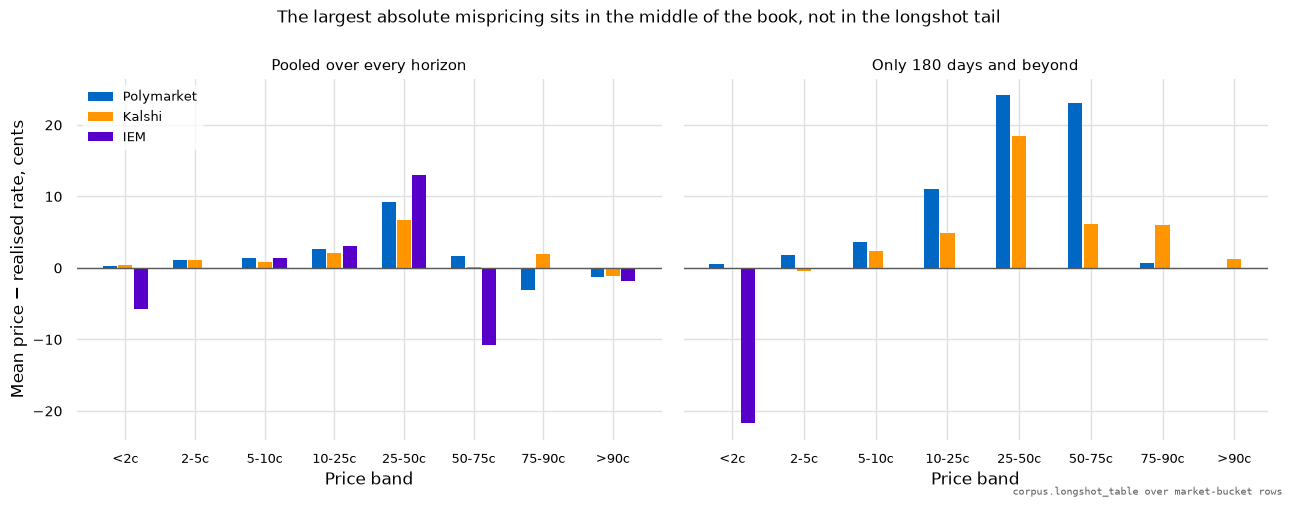

In [14]:
figure, (left, right) = pyplot.subplots(1, 2, figsize=(13, 5.0), sharey=True)
labels = [row[2] for row in corpus.PRICE_BANDS]
offsets = numpy.arange(len(labels))

for axis, buckets, title in (
        (left, None, "Pooled over every horizon"),
        (right, (5, 6), "Only 180 days and beyond")):
    for shift, name in ((-0.22, "polymarket"), (0.0, "kalshi"), (0.22, "iem")):
        picked = venue == name
        if buckets is not None:
            picked = picked & numpy.isin(rows["bucket"], buckets)
        gaps, xs = [], []
        for index, (lo, hi, _) in enumerate(corpus.PRICE_BANDS):
            cell = picked & (rows["price"] >= lo) & (rows["price"] < hi)
            if cell.sum() < (30 if name == "iem" else 60):
                continue
            gaps.append(100.0 * (rows["price"][cell].mean() - rows["outcome"][cell].mean()))
            xs.append(index + shift)
        axis.bar(xs, gaps, width=0.2, color=VENUE_COLOUR[name], label=VENUE_NAME[name])
    axis.axhline(0.0, color="0.35", lw=1.0)
    axis.set_xticks(offsets)
    axis.set_xticklabels(labels, fontsize=9)
    axis.set_xlabel("Price band")
    axis.set_title(title, fontsize=11)

left.set_ylabel("Mean price − realised rate, cents")
left.legend(loc="upper left", fontsize=9)
figure.suptitle("The largest absolute mispricing sits in the middle of the book, "
                "not in the longshot tail", fontsize=12)
figure.tight_layout()
stamp_source("corpus.longshot_table over market-bucket rows")
pyplot.show()

**Horizon and price band are separate corrections and both are needed, and the
interaction is much larger than either alone.** Read down the 25–50¢ row of the
table above. On Polymarket it runs **+2.10¢ inside a day, +11.86¢ at a month,
+19.86¢ at three to six months, +24.40¢ at six months to a year**. On Kalshi it
runs the other way at the short end — **−8.03¢ inside a day**, i.e. mid-range
contracts *underpriced* there — crosses zero between one and three months, and
reaches **+16.67¢ at six months to a year and +21.72¢ beyond**. Polymarket's
50–75¢ row does the same thing, −8.78¢ inside a day and +22.38¢ at six months to
a year.

So a single-number longshot correction is the wrong shape of instrument entirely.
What the corpus supports, stated as a rule of thumb with the caveat that these are
in-sample figures on settled markets and ignore fees: **inside a month, leave a
mid-range political price alone or nudge it up; from three months out, subtract
five to ten cents; from six months out, subtract fifteen to twenty-five.** Below
a dime, subtract a cent or less at any horizon. The tail is not where the money
is wrong.

## 4. The ladders — a row of deadlines as a distribution

This is the user's frame and it is the right one. A row of markets asking "does X
happen by T₁, by T₂, by T₃…" is not a set of unrelated questions: each price is
P(resolution ≤ Tᵢ), so **the row is a cumulative distribution over the resolution
date** and adjacent differences are the probability mass in each interval —
exactly as a row of option strikes differences into a density over price. That
makes a ladder checkable in a way no single market is: it can be monotone or not,
its differences can be positive or not, and its implied hazards can be read.

Three things have to be established before any of that means anything, and the
first two are restrictions the collectors found and this section confirms at
scale.

**A by-date ladder is a CDF only for an event that can happen at most once.** For
a recurring event the re-issues are *rolling* windows, not nested ones: "US bank
failure by October 31 2024" settled YES while "before December 2024" settled NO,
because the second window opened after the first closed. Differencing such a row
is meaningless. The Polymarket collector's `outcome_monotone` flag is the screen
for it.

**A ladder is only a CDF where its rungs are quoted at the same moment**, and
this one is new here. A ladder assembled across re-issued events mostly is not:
the rung that settled in February and the rung created in December never coexist.

In [15]:
ladders = corpus.ladder_price_coherence(kinds=("cumulative",), min_rungs=3, snapshots=16)
raw = json.loads((corpus.DATA / "polymarket_ladders.json").read_text())
cumulative = [lad for lad in raw["ladders"] if lad["kind"] == "cumulative"]

print("Attrition from 'a detected ladder' to 'a distribution anyone could have read'")
print(f"  {len(raw['ladders']):5,}  ladders detected, all kinds")
print(f"  {len(cumulative):5,}  of kind `cumulative` — the by-date CDFs")
print(f"  {sum(1 for l in cumulative if l['n_rungs'] == 2):5,}  of those have exactly TWO rungs "
      f"(median rung count {numpy.median([l['n_rungs'] for l in cumulative]):.0f})")
print(f"  {sum(1 for l in cumulative if l['n_rungs'] >= 3):5,}  have three or more")
print(f"  {len(ladders):5,}  had three or more rungs LIVE AT ONCE, with stored prices "
      f"— the scorable set")

pick = lambda key: numpy.asarray([lad[key] for lad in ladders], dtype=float)
events, simul, live = pick("n_events"), pick("simultaneous_frac"), pick("max_live_rungs")
print(f"\nOf the {len(ladders)} scorable ladders, {int((events > 1).sum())} span more than "
      f"one event.")
print(f"  single-event ladders: median {numpy.median(simul[events == 1]):.2f} of their rungs "
      f"were ever simultaneous")
print(f"  cross-event ladders:  median {numpy.median(simul[events > 1]):.2f}")
print(f"  rungs ever in a ladder: median {numpy.median(pick('all_rungs_ever')):.0f}, "
      f"max {pick('all_rungs_ever').max():.0f}")
print(f"  rungs live at once:     median {numpy.median(live):.0f}, max {live.max():.0f}")

Attrition from 'a detected ladder' to 'a distribution anyone could have read'
  3,787  ladders detected, all kinds
  1,046  of kind `cumulative` — the by-date CDFs
    568  of those have exactly TWO rungs (median rung count 2)
    478  have three or more
    241  had three or more rungs LIVE AT ONCE, with stored prices — the scorable set

Of the 241 scorable ladders, 20 span more than one event.
  single-event ladders: median 1.00 of their rungs were ever simultaneous
  cross-event ladders:  median 0.50
  rungs ever in a ladder: median 4, max 64
  rungs live at once:     median 3, max 28


**The median "cumulative ladder" on Polymarket is a pair of markets**, 568 of
1,046, and a two-rung ladder has one interval and cannot be incoherent in any
interesting way. Only 241 of the 1,046 — 23% — ever had three rungs quoted
simultaneously with stored prices. The full 18-rung Russia–Ukraine ceasefire row
the collector recovered is real as a *concept*, and at no moment in its life
could anyone have read more than **six** of its rungs at once.

That is the first substantive answer to "what does a ladder tell you that its
rungs do not": **less than the rung count suggests**, because the object is a
rolling window over the term structure rather than a fixed ladder. The long
concept ladder is a history of successive short ladders.

### Coherence in price, over each ladder's life

The collector scored ladders on their settled **outcomes** — whether the NO/YES
pattern along the deadline axis is monotone. That is a fact about the world. This
scores the **prices**: on sixteen dates spread over each ladder's life, read
every then-live rung's stored daily price, and ask whether the CDF is monotone in
the deadline and whether any adjacent difference is negative. A negative
difference is the market stating that the event is *less* likely to have happened
by a later date than by an earlier one.

In [16]:
snapshots = [snap for lad in ladders for snap in lad["snapshots"]]
monotone = pick("frac_monotone")

print(f"{len(ladders)} ladders, {len(snapshots):,} snapshots")
print(f"  monotone at every snapshot        {int((monotone >= 0.999).sum()):5,} "
      f"({(monotone >= 0.999).mean():5.1%} of ladders)")
print(f"  monotone at >= 90% of snapshots   {int((monotone >= 0.9).sum()):5,} "
      f"({(monotone >= 0.9).mean():5.1%})")
print(f"  never monotone                    {int((monotone <= 0.001).sum()):5,} "
      f"({(monotone <= 0.001).mean():5.1%})")
print(f"  snapshot-level monotone rate      {numpy.mean([s['monotone'] for s in snapshots]):5.1%}")
print(f"  median negative intervals/snapshot {numpy.median([s['n_negative'] for s in snapshots]):.0f}"
      f", worst single violation {min(s['worst_negative'] for s in snapshots):+.3f}")
print(f"  median staleness of the stalest live rung in a snapshot "
      f"{numpy.median([s['max_gap_days'] for s in snapshots]):.2f} days")
print(f"  median terminal mass (top rung's price) "
      f"{numpy.median([s['terminal_mass'] for s in snapshots]):.3f}")

linear = numpy.asarray([s["median_hazard_linear"] for s in snapshots])
force = numpy.asarray([s["median_hazard_force"] for s in snapshots])
finite = numpy.isfinite(linear) & numpy.isfinite(force)
print(f"\nImplied interval hazard, the two normalisations, over "
      f"{int(finite.sum()):,} snapshots:")
print(f"  linear   mass / days           median {numpy.median(linear[finite]):.5f} per day")
print(f"  force   −ln(1−h) / days        median {numpy.median(force[finite]):.5f} per day"
      f"   ({numpy.median(force[finite]) / numpy.median(linear[finite]) - 1:+.1%})")

241 ladders, 1,941 snapshots
  monotone at every snapshot          142 (58.9% of ladders)
  monotone at >= 90% of snapshots     168 (69.7%)
  never monotone                       10 ( 4.1%)
  snapshot-level monotone rate      86.1%
  median negative intervals/snapshot 0, worst single violation -0.983
  median staleness of the stalest live rung in a snapshot 0.53 days
  median terminal mass (top rung's price) 0.725

Implied interval hazard, the two normalisations, over 1,928 snapshots:
  linear   mass / days           median 0.01258 per day
  force   −ln(1−h) / days        median 0.01582 per day   (+25.7%)


**86.1% of snapshots are monotone and the median snapshot has zero negative
intervals.** The differencing operation is sound on real money most of the time:
59% of ladders never violate at any point in their lives, 70% violate at fewer
than one snapshot in ten. The worst single violation is −0.983, which is a rung
whose stale print and a live one disagree completely, not a tradeable arbitrage —
these are last trades, not quotes, so a stale print on one rung manufactures a
violation that was never executable. The median stalest live rung in a snapshot
is **half a day** old, so most snapshots are genuinely near-simultaneous; the
tail is not.

**The two hazard normalisations differ by 26% at the median** — 0.0126 per day
linear against 0.0158 as a continuous force of resolution. That reproduces the
metric catalogue's own worked example at corpus scale, and it matters for the
same reason: a flat *linear* hazard profile across rungs of widening width can
hide a genuinely rising force of resolution. Use the log form when comparing
intervals of different lengths, which on a date ladder is always.

**The top rung captures a median 0.725 of the probability mass**, so about 27% of
it sits beyond the last date the ladder lists. Reading the top rung as "the
chance this happens" is therefore wrong by a quarter on a typical Polymarket date
ladder — and by two thirds on Kalshi's, whose collector measured a median implied
mass of 0.35 on its date ladders. Neither venue lists far enough out to bound the
question.

### Does coherence track liquidity?

In [17]:
volume = pick("total_volume")
quintiles = numpy.quantile(volume, numpy.linspace(0, 1, 6))
print(f"{'quintile':10}{'ladders':>9}{'median volume':>16}{'frac monotone':>15}"
      f"{'neg/snapshot':>14}{'live rungs':>12}")
for index in range(5):
    upper = volume <= quintiles[index + 1] if index == 4 else volume < quintiles[index + 1]
    cell = (volume >= quintiles[index]) & upper
    if not cell.any():
        continue
    print(f"Q{index + 1:<9}{int(cell.sum()):9,}{numpy.median(volume[cell]):16,.0f}"
          f"{numpy.mean(monotone[cell]):15.3f}"
          f"{numpy.mean(pick('mean_negative_intervals')[cell]):14.2f}"
          f"{numpy.median(live[cell]):12.0f}")

print("\nAnd the same thing holding the ladder's width fixed instead")
print(f"{'live rungs':12}{'ladders':>9}{'frac monotone':>15}{'neg/snapshot':>14}"
      f"{'median volume':>16}")
for lo, hi, label in ((3, 3, "3"), (4, 5, "4–5"), (6, 9, "6–9"), (10, 99, "10+")):
    cell = (live >= lo) & (live <= hi)
    if cell.sum() < 3:
        continue
    print(f"{label:12}{int(cell.sum()):9,}{numpy.mean(monotone[cell]):15.3f}"
          f"{numpy.mean(pick('mean_negative_intervals')[cell]):14.2f}"
          f"{numpy.median(volume[cell]):16,.0f}")

for label, series in (("total ladder volume", volume),
                      ("median rung volume", pick("median_rung_volume")),
                      ("rungs live at once", live),
                      ("stalest-rung staleness", pick("median_max_gap_days"))):
    print(f"Spearman({label:24}, frac monotone) = "
          f"{corpus._spearman(series, monotone):+.3f}")

quintile    ladders   median volume  frac monotone  neg/snapshot  live rungs
Q1               48          42,535          0.808          0.22           3
Q2               48         188,215          0.850          0.16           3
Q3               49         765,256          0.882          0.14           3
Q4               47       2,946,223          0.919          0.09           3
Q5               49      30,065,558          0.861          0.32           5

And the same thing holding the ladder's width fixed instead
live rungs    ladders  frac monotone  neg/snapshot   median volume
3                 139          0.872          0.14         298,776
4–5                69          0.875          0.14       1,871,747
6–9                26          0.827          0.19       4,182,693
10+                 7          0.726          1.52      31,804,712
Spearman(total ladder volume     , frac monotone) = +0.178
Spearman(median rung volume      , frac monotone) = +0.227
Spearman(rungs live at o

**Barely, and the apparent relationship is mostly width.** Coherence rises across
the first four volume quintiles (0.808 → 0.919) and then *falls* in the top one
(0.861), which is not what a liquidity story predicts. The reason is in the last
column: the top quintile's ladders carry five live rungs against three, and a
wider ladder has more adjacent pairs to violate. Holding width fixed, coherence
falls monotonically with it — 0.872 at three rungs, 0.827 at six to nine, 0.726
at ten or more — and the rank correlation with rungs is **−0.264** against
**+0.178** with volume.

So the honest answer to "does coherence track liquidity" is: **weakly, and less
than it tracks how many rungs you are asking to line up.** A three-rung ladder on
a thin market is more often monotone than a ten-rung ladder on a deep one. That
is a warning about using coherence as a quality score — it is partly a measure of
how much was asked of the market, which is the same trap `liquidityNum` falls
into from the other direction.

### One ladder in full

The Russia–Ukraine ceasefire row is the object the user described, and it is worth
printing whole because it answers the section's last question.

In [18]:
flagship = max((lad for lad in ladders
                if "ceasefire" in str(lad["subject"]).lower()
                and "russia" in str(lad["subject"]).lower()),
               key=lambda lad: lad["all_rungs_ever"])

print(f"{flagship['subject']}   ({flagship['ladder_id']})")
print(f"  {flagship['all_rungs_ever']} rungs ever, across {flagship['n_events']} separate events; "
      f"at most {flagship['max_live_rungs']} live at once "
      f"({flagship['simultaneous_frac']:.0%} of the concept)")
print(f"  deadlines {flagship['min_deadline']} .. {flagship['max_deadline']}, "
      f"${flagship['total_volume']:,.0f} of volume across the rungs")
print(f"  monotone at {flagship['frac_monotone']:.0%} of its {flagship['n_snapshots']} snapshots; "
      f"outcome_monotone={flagship['outcome_monotone']}\n")

for snap in flagship["snapshots"]:
    print(f"  {snap['at']}  {snap['n_live']} live, "
          f"{'monotone' if snap['monotone'] else 'NOT monotone'}, "
          f"top rung {snap['terminal_mass']:.3f}, stalest {snap['max_gap_days']:.1f}d")
    for deadline, price, mass in zip(snap["deadlines"], snap["prices"],
                                     [None] + snap["interval_mass"]):
        bar = "#" * int(round(60 * price))
        extra = "" if mass is None else f"   +{mass:.3f} since the rung below"
        print(f"      {deadline}  {price:6.4f}  {bar:<60}{extra}")
    print()

russia x ukraine ceasefire <by> <date>   (cum-32ba1a1cd1fb)
  18 rungs ever, across 18 separate events; at most 6 live at once (33% of the concept)
  deadlines 2025-02-01 .. 2027-12-31, $309,423,788 of volume across the rungs
  monotone at 100% of its 11 snapshots; outcome_monotone=True

  2025-05-23  3 live, monotone, top rung 0.275, stalest 0.2d
      2025-05-31  0.0120  #                                                           
      2025-06-30  0.0850  #####                                                          +0.073 since the rung below
      2025-09-30  0.2750  ################                                               +0.190 since the rung below

  2025-07-25  3 live, monotone, top rung 0.500, stalest 0.8d
      2025-09-30  0.1150  #######                                                     
      2026-03-31  0.3300  ####################                                           +0.215 since the rung below
      2026-12-31  0.5000  ##############################       

**Monotone at every one of eleven snapshots across a full year, with the live
window rolling forward as rungs settle and new ones list.** In May 2025 the three
live rungs put 27.5% on a ceasefire by the end of September 2025; by August the
five live rungs put 59.5% on one by the end of 2026 with the mass spread across
four intervals; by May 2026 the ladder had 2.1% in the rest of that month, 22%
in June, and its median well out in 2026.

**The ceasefire market resolved YES on 9 May 2026**, the day after that last
snapshot, at a last daily print of 0.044.

That is the most useful thing in this section and it is not a happy result. **A
ladder that was internally coherent at every single reading was wrong about the
timing by most of a year, and its coherence gave no warning whatever.** Internal
coherence is a property of the arithmetic between the rungs — it says the rungs
are consistent with one another. It says nothing about whether they are
collectively right, and it cannot, because a smoothly interpolated curve is
exactly what a market maker quoting off one front rung produces. The reference
doc's own measurement of the open end of this same ladder is the mechanism:
fifteen monotone rungs whose lifetime volume beyond a year was $818, $976, $1,643
and $3,018.

**So: what does a ladder tell you that its rungs do not?** Three things, in
descending order of how much they are worth.

1. **The shape of the belief** — where the mass sits, an implied median date, and
   an implied hazard. None of that is visible in any single rung and all of it is
   visible in the row. This is the real gain and it is what makes the frame right.
2. **An arithmetic check on the rungs.** A negative interval is either an
   arbitrage or a stale quote, and either way it is information about the
   *quoting* that a single price cannot give you. 14% of snapshots here fail it.
3. **Not accuracy, and not a confidence signal.** A coherent ladder is not a
   well-forecast ladder. Coherence is cheap to manufacture — one real rung and an
   interpolation produces it — and on this corpus it correlates with ladder width
   more than with liquidity.

### Kalshi's ladders, for contrast

Kalshi labels the shape rather than leaving it to inference: `mutually_exclusive`
plus `strike_type` plus the rung label distinguishes a survival ladder from a CDF
from a partition. Its collector scored 3,137 open ladders on **synchronous
mid-quotes**, which is the better measurement — mids rather than last prints, so
a stale-print violation cannot occur.

In [19]:
for filename, label in (("kalshi_live_ladder_coherence.jsonl", "open ladders, synchronous mids"),
                        ("kalshi_closed_ladder_coherence.jsonl", "closed date-CDF snapshots")):
    payload = [json.loads(line) for line in (corpus.DATA / filename).read_text().splitlines() if line]
    print(f"\nKalshi — {label}: {len(payload):,} rows")
    print(f"  {'group':14}{'n':>7}{'monotone':>10}{'≤1¢':>8}{'≤5¢':>8}{'worst':>8}"
          f"{'median implied mass':>21}")
    groups = [("kind=" + k, [r for r in payload if r.get("kind") == k])
              for k in sorted({r.get("kind") for r in payload})]
    if any("cat" in r for r in payload):
        groups += [("cat=" + c, [r for r in payload if r.get("cat") == c])
                   for c in sorted({r.get("cat") for r in payload if r.get("cat")})]
    for name, subset in groups:
        if not subset:
            continue
        worst = numpy.asarray([r["max_violation"] for r in subset], dtype=float)
        mass = numpy.asarray([r["implied_mass"] for r in subset], dtype=float)
        print(f"  {name:14}{len(subset):7,}"
              f"{numpy.mean([r['monotone'] for r in subset]):10.1%}"
              f"{numpy.mean(worst <= 0.01):8.1%}{numpy.mean(worst <= 0.05):8.1%}"
              f"{worst.max():8.3f}{numpy.nanmedian(mass):21.3f}")


Kalshi — open ladders, synchronous mids: 3,137 rows
  group               n  monotone     ≤1¢     ≤5¢   worst  median implied mass
  kind=date         152     90.1%   94.7%   98.0%   0.345                0.352
  kind=strike     2,985     91.5%   94.2%   97.0%   0.435                0.790
  cat=Economics     341     71.8%   79.2%   87.4%   0.435                0.825
  cat=Elections   2,161     96.8%   97.8%   98.8%   0.435                0.780
  cat=Financials    471     79.8%   88.3%   94.9%   0.375                0.810
  cat=Politics      164     93.9%   96.3%   98.8%   0.130                0.472

Kalshi — closed date-CDF snapshots: 105 rows
  group               n  monotone     ≤1¢     ≤5¢   worst  median implied mass
  kind=date         105     65.7%   87.6%   97.1%   0.130                0.610


**Measured on mids, Kalshi's ladders are cleaner than Polymarket's on last
prints — and the comparison is not fair, which is itself the point.** 90–92%
monotone and 94% within a cent, against Polymarket's 86% of snapshots; but
Polymarket cannot be measured on mids at all, because a closed market has no
book and its stored path is trades only. **The venue that publishes quote history
is the only venue where ladder coherence can be measured without a stale-print
confound.** That is a data-availability difference masquerading as a quality
difference, and anyone comparing the two numbers should know which they are
looking at.

Two things in Kalshi's table are worth carrying anyway. Its **Economics** ladders
are the least coherent of its four categories at 71.8%, and Economics is the most
arithmetic category it has — wide strike ladders whose deep out-of-the-money rungs
go one-sided. And its **date ladders carry a median implied mass of 0.352**
against 0.79 on its strike ladders: a typical Kalshi "when will X happen" ladder
lists dates capturing barely a third of the probability. Both point the same way
as the Polymarket terminal-mass figure above.

## 5. Which metrics matter — the deliverable

The metric catalogue lists every measure of market quality that public data
supports: 17 families across four venues, 40 `yes` cells, 10 `partial`, 18 `no`,
and 9 entries in `NOT_COMPUTABLE`. It deliberately has **no composite score**,
because collapsing these is how `liquidityNum` came to rank a zero-bid contract
as its event's most liquid.

The question this section answers is narrower and it is the one that decides
which of them to use: **does the metric separate a calibrated market from a
miscalibrated one?** Everything below is measured against settled outcomes, so a
metric either earns its place or does not.

### First, the three fields that cannot be tested at all

In [20]:
polymarket_markets = [m for m in panel.markets if m.venue == "polymarket"]
print(f"Vendor-reported quality fields on Polymarket's {len(polymarket_markets):,} "
      f"CLOSED markets")
print(f"{'field':24}{'present':>18}{'distinct values':>17}{'median':>12}")
for field in ("liquidity_num", "competitive", "vendor_spread", "best_bid", "best_ask",
              "event_open_interest", "volume_num", "uma_bond"):
    values = [m.quality.get(field) for m in polymarket_markets]
    finite = [v for v in values if v is not None and numpy.isfinite(float(v))]
    share = len(finite) / len(polymarket_markets)
    print(f"{field:24}{f'{len(finite):,} ({share:.1%})':>18}"
          f"{len({round(float(v), 6) for v in finite}):17,}"
          f"{numpy.median(finite) if finite else float('nan'):12.4g}")

Vendor-reported quality fields on Polymarket's 46,223 CLOSED markets
field                              present  distinct values      median
liquidity_num                6,261 (13.5%)              246           0
competitive                  6,277 (13.6%)               10           0
vendor_spread              46,223 (100.0%)              316       0.001
best_bid                    11,918 (25.8%)              206       0.999
best_ask                   46,223 (100.0%)              271       0.001


event_open_interest         44,784 (96.9%)            3,145       302.3


volume_num                  44,061 (95.3%)           43,922   1.718e+04


uma_bond                    46,093 (99.7%)               27         500

**`liquidityNum` and `competitive` are retained on 13.5% of closed markets, with
246 and ten distinct values between them, both with a median of zero.** They
cannot be tested retrospectively, on this corpus or any other, because Polymarket
does not keep them once a market closes.

That is a sharper finding than "`liquidityNum` is misleading". The collectors and
the reference doc both established what it *means* — total resting-bid notional
across both token books, which is why a zero-bid contract can outrank a
front-runner. This adds that **nobody can ever check whether it worked**, because
the field is not preserved alongside the outcome. A live filter that cannot be
validated against settlement is an act of faith, and `competitive` — Polymarket's
own book-quality score — is in exactly the same position. `spread` is retained on
100% of markets and reads 0.001 on books with no bid at all, so it is present and
constant, which is untestable for the opposite reason.

**Availability is itself a quality metric, and it is the one nobody lists.** On
this axis Kalshi is in a different class: its historical candles carry bid, ask,
mid, volume and open interest on every day of a settled market's life, for ever,
so every measure below is computable after the fact.

### The confound that makes the obvious version of this table wrong

Almost every quality metric is partly a proxy for the **price level**. Relative
spread is `spread / mid`, so a 2¢ contract has a huge one by arithmetic alone. A
market that "never moves" is a market priced at 2¢. And the price level is itself
the strongest predictor of the realised rate, since a 2¢ contract settles NO
about 99.8% of the time. So a naive sweep ranks metrics by how well they sort
markets by price, and calls it quality.

Two things are therefore held fixed in every number below. **Horizon**, by
restricting to one band at a time — horizon is the strongest predictor of
miscalibration in this whole notebook, so any metric correlated with market
lifetime would otherwise win by proxying it. And **the price mix**, by
post-stratifying each metric bin onto the whole sample's distribution of prices.

The raw column is printed beside the standardised one, because the difference
between them is the finding.

In [21]:
print("How strongly each candidate metric is simply a proxy for the price")
mid_band = (rows["bucket"] >= 3) & (rows["bucket"] <= 6)
for name, field in (("kalshi", "median_rel_spread"), ("kalshi", "median_spread"),
                    ("kalshi", "max_abs_move"), ("kalshi", "traded_frac"),
                    ("kalshi", "peak_open_interest"), ("kalshi", "volume"),
                    ("polymarket", "information_rate"), ("polymarket", "median_abs_move"),
                    ("polymarket", "frac_unchanged"), ("polymarket", "volume_num"),
                    ("polymarket", "n_points")):
    cell = mid_band & (venue == name)
    values = numpy.array([
        (m.quality.get(field) if m.quality.get(field) is not None else numpy.nan)
        for m in panel.markets], dtype=float)[rows["m_index"][cell]]
    good = numpy.isfinite(values)
    if good.sum() < 200:
        continue
    rho = corpus._spearman(values[good], rows["price"][cell][good])
    flag = "  <- mostly a price proxy" if abs(rho) >= 0.45 else ""
    print(f"  {VENUE_NAME[name]:11}{field:22} Spearman with price {rho:+.3f}"
          f"   n={int(good.sum()):6,}{flag}")

How strongly each candidate metric is simply a proxy for the price
  Kalshi     median_rel_spread      Spearman with price -0.646   n=10,451  <- mostly a price proxy
  Kalshi     median_spread          Spearman with price +0.312   n=10,451
  Kalshi     max_abs_move           Spearman with price +0.452   n=10,494  <- mostly a price proxy
  Kalshi     traded_frac            Spearman with price +0.239   n=10,542
  Kalshi     peak_open_interest     Spearman with price +0.086   n=10,542
  Kalshi     volume                 Spearman with price +0.120   n=10,542
  Polymarket information_rate       Spearman with price +0.632   n=21,986  <- mostly a price proxy
  Polymarket median_abs_move        Spearman with price +0.564   n=21,986  <- mostly a price proxy
  Polymarket frac_unchanged         Spearman with price -0.449   n=21,986


  Polymarket volume_num             Spearman with price -0.083   n=21,333
  Polymarket n_points               Spearman with price -0.242   n=21,986


In [22]:
POLYMARKET_METRICS = ["volume_num", "event_open_interest", "n_points", "distinct_levels",
                      "levels_per_point", "frac_unchanged", "median_abs_move",
                      "max_abs_move", "largest_gap_days", "information_rate",
                      "resolution_chars"]
KALSHI_METRICS = ["volume", "peak_open_interest", "traded_frac", "two_sided_frac",
                  "median_rel_spread", "median_spread", "n_distinct_prices",
                  "frac_periods_unchanged", "median_abs_move", "max_abs_move",
                  "n_periods", "life_days"]


def ranking(name, names, mask, title):
    """Quintile bins of each metric, ranked by what it buys once price is held fixed."""
    result = corpus.metric_discrimination(panel, rows, names, mask=mask,
                                          n_bins=5, min_per_bin=60)
    usable = sorted((r for r in result if r["usable"]), key=lambda r: r["d_abs_bias_std"])
    print(f"\n{title}   ({int(mask.sum()):,} rows)")
    print(f"{'metric':23}{'markets':>8}{'RAW Δ|bias|':>13}{'STD |b| low':>13}"
          f"{'STD |b| high':>14}{'STD Δ|bias|':>13}{'ρ':>7}{'Δ brier':>9}")
    for row in usable:
        print(f"{row['metric']:23}{row['n_markets']:8,}{row['d_abs_bias']:+13.4f}"
              f"{row['abs_bias_std_lo']:13.4f}{row['abs_bias_std_hi']:14.4f}"
              f"{row['d_abs_bias_std']:+13.4f}{row['rho_abs_bias_std']:+7.2f}"
              f"{row['d_brier_std']:+9.4f}")
    for row in result:
        if not row["usable"]:
            print(f"  not testable: {row['metric']:22} n={row['n']:,}  {row['reason']}")
    return result


for lo, hi, label in ((3, 4, "30–180 days"), (5, 6, "180 days – 2 years")):
    band = (rows["bucket"] >= lo) & (rows["bucket"] <= hi)
    ranking("polymarket", POLYMARKET_METRICS, band & (venue == "polymarket"),
            f"POLYMARKET, horizon held to {label}")
    ranking("kalshi", KALSHI_METRICS, band & (venue == "kalshi"),
            f"KALSHI, horizon held to {label}")


POLYMARKET, horizon held to 30–180 days   (19,673 rows)
metric                  markets  RAW Δ|bias|  STD |b| low  STD |b| high  STD Δ|bias|      ρ  Δ brier
volume_num               14,247      -0.1587       0.1395        0.0011      -0.1384  -1.00  +0.0374
median_abs_move          14,738      +0.0159       0.1209        0.0272      -0.0937  -1.00  +0.1191
n_points                 14,738      -0.1421       0.1000        0.0250      -0.0750  -0.90  -0.0206
distinct_levels          14,738      -0.0522       0.1020        0.0423      -0.0598  -1.00  +0.0135
information_rate         14,738      +0.0677       0.0307        0.0017      -0.0290  -0.40  +0.1826
levels_per_point         14,738      +0.0953       0.0940        0.0675      -0.0265  -0.60  +0.0572
max_abs_move             14,738      +0.0114       0.0306        0.0058      -0.0248  -0.10  +0.1557
largest_gap_days         14,738      +0.0006       0.0533        0.0462      -0.0071  +0.00  +0.0012
event_open_interest      13,964   


POLYMARKET, horizon held to 180 days – 2 years   (2,313 rows)
metric                  markets  RAW Δ|bias|  STD |b| low  STD |b| high  STD Δ|bias|      ρ  Δ brier
volume_num                2,210      -0.2338       0.2166        0.0326      -0.1840  -0.90  +0.0287
median_abs_move           2,231      -0.0812       0.1804        0.0137      -0.1666  -1.00  +0.1375
levels_per_point          2,231      +0.0610       0.1881        0.0921      -0.0960  -0.90  +0.0646
distinct_levels           2,231      +0.0269       0.1862        0.0998      -0.0864  -1.00  +0.0555
n_points                  2,231      -0.1012       0.1570        0.1342      -0.0227  -0.30  -0.0061
information_rate          2,231      +0.0532       0.0451        0.0356      -0.0094  -0.40  +0.2031
resolution_chars          2,231      +0.0107       0.1169        0.1252      +0.0083  +0.30  -0.0031
event_open_interest       2,027      +0.0242       0.1178        0.1272      +0.0094  +0.50  +0.0068
largest_gap_days          2,

Read `STD Δ|bias|`: the change in absolute bias from the metric's bottom quintile
to its top, with the price mix held fixed. Negative means the metric picks better
markets. `ρ` is the rank correlation across all five bins, so a large Δ with a
small ρ means the metric works only at the ends and is not usable as a threshold.

**What survives standardisation.** Four measures do real work and they are the
same four on both venues in different clothing:

| What it measures | Polymarket field | Kalshi field | Δ\|bias\|, 30–180d | Δ\|bias\|, 180d–2y |
| --- | --- | --- | --- | --- |
| Did anyone trade it | `volume_num` | `volume` | −13.8 / −4.9 pp | **−18.4 / −12.1 pp** |
| Did the price move at all | `median_abs_move` | `median_abs_move` | −9.4 / −5.3 pp | **−16.7 / −12.2 pp** |
| Did it trade *often* | `distinct_levels` | `traded_frac` | −6.0 / −4.6 pp | −8.6 / **−13.9 pp** |
| Did anyone hold it | *(not retained)* | `peak_open_interest` | — / −4.7 pp | — / **−12.2 pp** |

Every one of those has a rank correlation of −0.7 to −1.0 across all five bins, so
they order markets rather than working only at the extremes, and every one gets
*stronger* at range — which is what a filter for long-dated markets needs to do.

**Polymarket's `volume_num` is the single strongest discriminator in this
notebook**, and that is awkward, because the reference doc's instruction is
"**never** use `volume` or `liquidity` as a quality filter" — on the good evidence
that 88% of a flagship event's volume sat in sub-2¢ outcomes and that a third of
2024 volume was estimated to be wash trading. Both things are true, and the
resolution is that they are answers to different questions. As a measure of
*interest*, volume is worthless: it is unauditable, `volumeClob` equals
`volumeNum` at every percentile, and it turns over 128× on a two-year market. As a
*screen*, it is excellent, because what it actually separates is markets that
traded from markets that did not, and the bottom quintile is where the
miscalibration lives — bias 15.9 points at 30–180 days against 0.05 in the top
quintile. Use it as a floor, never as a ranking, and never read its magnitude as
depth.

**Open interest is the metric whose value depends entirely on where you get it.**
Kalshi's `peak_open_interest` — recovered from the candle path, because the
settled market row is zeroed — cuts bias by 12.2 points at range. Polymarket's
`event_open_interest`, which is what the closed corpus retains, does **nothing**:
−0.5 points at 30–180 days and +0.9 beyond. The reference doc recommends
"`openInterest` and depth you compute yourself" over volume, and on this corpus
that is backwards for Polymarket and right for Kalshi. The difference is not the
concept but the vintage: an event-level figure read after settlement is not the
peak a market ever carried.

### The metrics that sound good and do nothing

**`median_rel_spread` is the headline failure, and it is not merely useless.** It
is the metric the reference doc singles out (§1.4: "Absolute spread is useless
here… relative spread ≤ 10%") and the one carrying the Kalshi collector's
three-part gate. Its rank correlation with the price is **−0.646**, which is
mostly arithmetic: relative spread is `spread / mid`, so a cheap contract has a
big one whatever its book looks like. Its raw Δ|bias| looks helpful (−3.9 points
at 30–180 days), its bottom quintile has a base rate of **0.709** against 0.021
in the top, and once the price mix is held fixed its ρ is **+0.20** — so it does
not order the bins at all and there is no threshold to set. The sweep below shows
what happens if you set one anyway.

**`information_rate` and `max_abs_move` are the same story with the sign flipped.**
They correlate +0.63 and +0.45 with the price (as does `median_abs_move` at +0.56,
which is why it needed standardising too), they look actively harmful raw, and
standardised they are worth one to three points with signs that flip across
horizon bands — `max_abs_move` reads −2.5 points at 30–180 days and **+7.4**
beyond. A market that moves a lot is not a better market; it is usually a more
expensive one, and at long horizon it is one that got surprised.

**`resolution_chars` buys nothing: +1.6 points at 30–180 days, +0.8 beyond, ρ
+0.6 and +0.3.** Polymarket's resolution prose is genuinely rigorous — inclusion
lists, exclusion lists, named historical precedents, ten-day continuity tests —
and its median length is 1,155 characters against Kalshi's 122. Longer prose does
not buy calibration. Read that as evidence against **the length proxy**, not
against reading the text: what the doc's filter 6 asks for is a named source and
a duration test, and a character count is a poor stand-in for either. The
catalogue's `names_machine_checkable_source` is the right test and Polymarket's
closed corpus does not retain enough `resolution_source` values to run it.

**And two that run backwards, monotonically, which makes them usable upside
down.** `frac_unchanged` on Polymarket reads **+7.0 points at 30–180 days and
+13.9 beyond**, and Kalshi's `frac_periods_unchanged` **+3.7 and +11.6**, both with
ρ between +0.9 and +1.0 — the cleanest monotone relationships anywhere in the two
tables. The more days a market's price sat still, the worse calibrated it was.
That is the same information as `median_abs_move` pointing the other way round,
and a floor on movement is the usable form of it.

`two_sided_frac` on Kalshi is the one genuine horizon-dependent case: **+2.3
points at 30–180 days and −12.3 beyond**. A two-sided book matters at range and
not nearby. Do not carry it as a rule without the horizon attached.

One more that does nothing and is worth naming so nobody spends time on it:
`largest_gap_days` — −0.7 points at 30–180 days, +4.7 beyond, ρ +0.00 then +0.40.

And one that should be left alone rather than used in either direction. Kalshi's
`life_days` and `n_periods` read +1.4 and −0.05 points at 30–180 days and **−5.8
and −5.9 beyond**, a clean sign flip, and +4.5 pooled over everything past 30 days.
A variable whose standardised effect changes sign when you move the horizon window
is still entangled with horizon — how long a market lived determines which buckets
it can appear in at all — so none of those three numbers is measuring quality.
Market age is the cheapest thing on this list to compute and it is the one to
ignore.

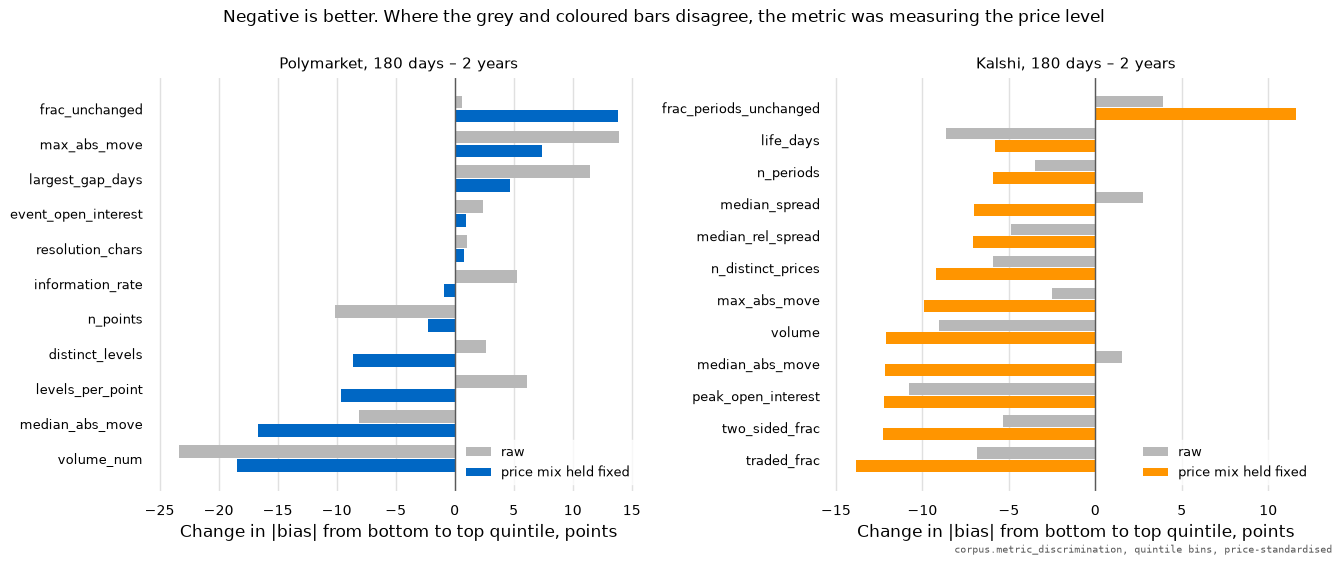

In [23]:
figure, axes = pyplot.subplots(1, 2, figsize=(13.5, 5.6))
band = (rows["bucket"] >= 5) & (rows["bucket"] <= 6)
for axis, name, names in ((axes[0], "polymarket", POLYMARKET_METRICS),
                          (axes[1], "kalshi", KALSHI_METRICS)):
    result = [r for r in corpus.metric_discrimination(
        panel, rows, names, mask=band & (venue == name), n_bins=5, min_per_bin=60)
        if r["usable"]]
    result.sort(key=lambda r: r["d_abs_bias_std"])
    offsets = numpy.arange(len(result))
    # Two bars per metric: the raw effect, and the effect with the price mix held
    # fixed. Where the pair disagrees, the metric was sorting markets by price.
    axis.barh(offsets + 0.2, [100 * r["d_abs_bias"] for r in result], height=0.36,
              color="0.72", label="raw")
    axis.barh(offsets - 0.2, [100 * r["d_abs_bias_std"] for r in result], height=0.36,
              color=VENUE_COLOUR[name], label="price mix held fixed")
    axis.axvline(0.0, color="0.35", lw=1.0)
    axis.set_yticks(offsets)
    axis.set_yticklabels([r["metric"] for r in result], fontsize=9)
    axis.set_xlabel("Change in |bias| from bottom to top quintile, points")
    axis.set_title(f"{VENUE_NAME[name]}, 180 days – 2 years", fontsize=11)
    axis.legend(loc="lower right", fontsize=9)
    axis.grid(axis="y", visible=False)

figure.suptitle("Negative is better. Where the grey and coloured bars disagree, "
                "the metric was measuring the price level", fontsize=12)
figure.tight_layout()
stamp_source("corpus.metric_discrimination, quintile bins, price-standardised")
pyplot.show()

### The thresholds a person should actually use

A quintile split says a metric orders markets; it does not say where to cut. The
sweep below gives, for each candidate threshold, the share of markets that
survive it and the calibration of what survives — with `kept` printed beside
every row, because a filter that improves calibration while keeping nothing is
not a filter. Horizon is held to 30 days and beyond, which is the range where any
of this matters.

In [24]:
def sweep(name, metric, thresholds, direction="above"):
    band = rows["bucket"] >= 3
    result = corpus.threshold_sweep(panel, rows, metric, thresholds,
                                    mask=band & (venue == name), direction=direction)
    arrow = ">=" if direction == "above" else "<="
    print(f"\n{VENUE_NAME[name]} — {metric} {arrow} t, at 30 days and beyond")
    print(f"{'threshold':>12}{'kept':>8}{'markets':>9}{'bias (std)':>12}"
          f"{'Δ|bias|':>10}{'brier (std)':>13}{'weight cov':>12}")
    for row in result:
        if not row.get("usable"):
            print(f"{row['threshold']:12.4g}{row['kept_frac']:8.1%}"
                  f"{'  — too few markets to read —':>44}")
            continue
        print(f"{row['threshold']:12.4g}{row['kept_frac']:8.1%}{row['n_markets']:9,}"
              f"{row['bias_std']:+12.4f}{row['d_abs_bias_std']:+10.4f}"
              f"{row['brier_std']:13.4f}{row['weight_covered']:12.2f}")


sweep("polymarket", "volume_num", [0, 1e3, 5e3, 1e4, 5e4, 1e5, 5e5, 1e6])
sweep("polymarket", "median_abs_move", [0, 0.001, 0.002, 0.005, 0.01])
sweep("kalshi", "peak_open_interest", [0, 1e3, 5e3, 1e4, 5e4, 1e5])
sweep("kalshi", "traded_frac", [0, 0.1, 0.25, 0.4, 0.5, 0.65, 0.8])
sweep("kalshi", "median_rel_spread", [0.05, 0.1, 0.2, 0.3, 0.5], direction="below")


Polymarket — volume_num >= t, at 30 days and beyond
   threshold    kept  markets  bias (std)   Δ|bias|  brier (std)  weight cov
           0   97.0%   14,250     +0.0762   +0.0009       0.0974        1.00
        1000   93.7%   13,582     +0.0720   -0.0032       0.0977        1.00
        5000   82.2%   11,680     +0.0597   -0.0155       0.0995        1.00
       1e+04   74.6%   10,512     +0.0538   -0.0215       0.1011        1.00
       5e+04   50.8%    6,785     +0.0363   -0.0390       0.1059        1.00
       1e+05   40.5%    5,256     +0.0292   -0.0461       0.1080        1.00
       5e+05   20.6%    2,449     +0.0109   -0.0643       0.1175        1.00
       1e+06   14.4%    1,644     +0.0007   -0.0746       0.1255        1.00

Polymarket — median_abs_move >= t, at 30 days and beyond
   threshold    kept  markets  bias (std)   Δ|bias|  brier (std)  weight cov
           0  100.0%   14,741     +0.0752   +0.0000       0.0974        1.00
       0.001   59.6%    9,667     +0.0612 

**The relative-spread sweep is the one to look at, and it is not a null result —
it is an inversion.** Cutting at the reference doc's ≤10% takes the standardised
bias from +2.8 points to **−12.1**, making |bias| **9.4 points worse** and taking
the standardised Brier from 0.101 to 0.182, while keeping 23% of markets. Cutting
at ≤5% takes it to −24.7 points, worse by 22.0, on 8.4%. The direction that helps
is the **loose** one: ≤50% improves |bias| by 2.7 points and keeps 65%.

The mechanism is arithmetic rather than mysterious: a tight *relative* spread
requires a high mid, so the filter selects expensive contracts, which are the
contracts this corpus prices too low. The `weight cov` column stays at 1.00
throughout, so this is not an artefact of the filter emptying whole price strata —
under five strata each surviving bin still has rows in every band.

**But that is also as far as the measurement goes, and the honest verdict is
weaker than "tightness is harmful".** Five coarse strata cannot fully remove a
−0.646 correlation, so residual price sorting inside each stratum is the most
likely explanation, and the cell below tests it. The conclusion that does survive
is the one that matters operationally: **relative spread is so tightly coupled to
the price level that it cannot be evaluated independently of what it selects for,
and every threshold in the recommended direction makes calibration worse on this
corpus.** A filter with those two properties should not be in a gate.

### Is any of that an artefact of how coarsely the price was held fixed?

The standardisation uses five price strata, and relative spread correlates −0.646
with the price. Five coarse bands cannot fully remove a correlation that strong —
inside the 50–80¢ stratum the tight-spread markets will still sit at the top of
the band. So the check that matters is whether the conclusions move when the
strata are doubled to ten. If the discriminators survive and the price proxies
collapse, the stratification is doing its job; if everything moves, none of
section 5 is safe.

In [25]:
FINER = tuple((lo, hi, f"{lo:.2f}") for lo, hi in zip(
    (0.00, 0.02, 0.05, 0.10, 0.20, 0.35, 0.50, 0.65, 0.80, 0.92),
    (0.02, 0.05, 0.10, 0.20, 0.35, 0.50, 0.65, 0.80, 0.92, 1.01)))
band = rows["bucket"] >= 3

print("Standardised Δ|bias| under five price strata and under ten")
print(f"{'venue':12}{'metric':22}{'5 strata':>11}{'ρ':>7}{'10 strata':>12}{'ρ':>7}"
      f"{'min weight cov':>16}")
for name, names in (("polymarket", ["volume_num", "median_abs_move", "distinct_levels",
                                    "frac_unchanged", "information_rate",
                                    "event_open_interest", "resolution_chars"]),
                    ("kalshi", ["volume", "peak_open_interest", "traded_frac",
                                "median_abs_move", "median_rel_spread", "median_spread",
                                "two_sided_frac", "life_days"])):
    mask = band & (venue == name)
    coarse = {r["metric"]: r for r in corpus.metric_discrimination(
        panel, rows, names, mask=mask) if r["usable"]}
    fine = {r["metric"]: r for r in corpus.metric_discrimination(
        panel, rows, names, mask=mask, bands=FINER) if r["usable"]}
    for metric in names:
        if metric not in coarse or metric not in fine:
            continue
        a, b = coarse[metric], fine[metric]
        print(f"{VENUE_NAME[name]:12}{metric:22}{a['d_abs_bias_std']:+11.4f}"
              f"{a['rho_abs_bias_std']:+7.2f}{b['d_abs_bias_std']:+12.4f}"
              f"{b['rho_abs_bias_std']:+7.2f}"
              f"{min(b['weight_covered_lo'], b['weight_covered_hi']):16.2f}")

print("\nAnd the relative-spread threshold sweep under ten strata")
print(f"{'threshold':>12}{'kept':>8}{'bias (std)':>12}{'Δ|bias|':>10}{'weight cov':>12}")
for row in corpus.threshold_sweep(panel, rows, "median_rel_spread",
                                  [0.05, 0.1, 0.2, 0.3, 0.5],
                                  mask=band & (venue == "kalshi"),
                                  direction="below", bands=FINER):
    if not row.get("usable"):
        continue
    print(f"{row['threshold']:12.2f}{row['kept_frac']:8.1%}{row['bias_std']:+12.4f}"
          f"{row['d_abs_bias_std']:+10.4f}{row['weight_covered']:12.2f}")

Standardised Δ|bias| under five price strata and under ten
venue       metric                   5 strata      ρ   10 strata      ρ  min weight cov


Polymarket  volume_num                -0.1371  -1.00     -0.1292  -1.00            1.00
Polymarket  median_abs_move           -0.0965  -1.00     -0.0798  -1.00            1.00
Polymarket  distinct_levels           -0.0469  -0.90     -0.0408  -0.90            1.00
Polymarket  frac_unchanged            +0.0792  +1.00     +0.0829  +1.00            1.00
Polymarket  information_rate          -0.1170  -0.90     -0.0654  -0.70            0.75
Polymarket  event_open_interest       +0.0015  +0.50     -0.0000  -0.50            1.00
Polymarket  resolution_chars          +0.0147  +0.10     +0.0086  +0.00            1.00
Kalshi      volume                    -0.0740  -0.90     -0.0712  -0.90            1.00
Kalshi      peak_open_interest        -0.0791  -0.90     -0.0734  -0.90            1.00
Kalshi      traded_frac               -0.0918  -1.00     -0.0827  -1.00            1.00
Kalshi      median_abs_move           -0.0906  -0.90     -0.0777  -0.70            1.00
Kalshi      median_rel_spread   

**Doubling the strata leaves the answer alone where it counts, and removes the one
result that was suspect.** The four discriminators move by a tenth of their own
size and keep their rank correlations exactly: `volume_num` −0.137 → −0.129,
`traded_frac` −0.092 → −0.083, `median_abs_move` −0.097 → −0.080,
`peak_open_interest` −0.079 → −0.073, every one still ρ −0.9 or −1.0. The three
nulls stay null with ρ falling to zero — `event_open_interest` +0.0015 → −0.0000,
`resolution_chars` +0.015 → +0.009. And `frac_unchanged` stays +0.08 at ρ +1.00 in
both, so the backwards-running metric is backwards-running robustly.

**`median_rel_spread` collapses, which is the confirmation.** Under five strata it
reads +0.010 at ρ +0.60; under ten it reads −0.014 at ρ **−0.10**. A real effect
does not evaporate when you look more carefully at the thing it was confounded
with. Its *threshold* behaviour survives at ≤0.10 (+10.5 points worse, full weight
coverage), so the operational verdict stands while the causal one does not, which
is exactly the distinction drawn above. `information_rate` and `two_sided_frac`
weaken the same way — `information_rate` from −0.117 to −0.065 with weight
coverage falling to 0.75, which is the standardisation telling you it has run out
of comparable markets.


**The thresholds worth carrying**, each stated with what it costs:

| Venue | Rule | Keeps | Standardised bias |
| --- | --- | --- | --- |
| Polymarket | `volume_num ≥ $100,000` | 41% | +2.9 pp, from +7.5 |
| Polymarket | `volume_num ≥ $1,000,000` | 14% | **+0.1 pp** |
| Kalshi | `peak_open_interest ≥ $10,000` | 56% | +0.5 pp, from +2.8 |
| Kalshi | `peak_open_interest ≥ $50,000` | 37% | −0.1 pp |
| Kalshi | `traded_frac ≥ 0.4` | 42% | +0.4 pp |
| Polymarket | `median_abs_move ≥ 0.002` (about its median) | 49% | +5.0 pp, from +7.5 |

Three warnings on that table. These are **in-sample thresholds on a settled
corpus** and the quintile boundaries were chosen by the data, so the exact cut
points will not transfer — treat the shape (a floor helps, a ceiling does not, the
floor can be loose, volume and open interest are near-interchangeable) as the
finding and re-derive the number on whatever population is actually being traded.

**The standardised Brier gets worse as every one of these filters tightens**, even
while the bias improves — Polymarket's runs 0.0974 → 0.1255 as the volume floor
goes to $1M. That is not a contradiction: the filters remove the dead markets whose
prices sat at 2¢ and were nearly always right in absolute terms, leaving a harder
population that is *unbiased* but no more accurate. A floor buys you a price you
can read as a probability. It does not buy you a better forecast.

And every one of them removes more than half the universe at range, which is the
same wall the reference doc hit from the depth side: the filter that makes prices
trustworthy also removes most of the markets whose prices you wanted.

## 6. What this supports, and what it does not

**Supported: the horizon gradient, on three venues independently.** Inside a week
every venue in this corpus is calibrated to within a fifth of a point. From a
month out prices sit above outcomes, and at one to two years the gap is +14.6
points on Polymarket (n=82 markets), +9.4 on Kalshi (n=990) and −10.4 on IEM
(n=48). Brier skill falls from 0.77 to 0.11 pooled. The bootstrap intervals,
clustered on markets, exclude zero from a week out on Polymarket and from three
months out on Kalshi. **This is the evidence the published literature does not
have**, because the published literature's longest bin is "1mo+", and the answer
is that the one-month shape continues and roughly doubles again by two years.

**Supported, and the stronger claim: it is not composition.** Restricting to
markets that lived over a year, so that the same markets appear in every bucket
and the realised rate is fixed by construction, leaves the gradient intact and
makes it larger on Polymarket. The same markets, on the same questions, were
further from their own eventual answers the further out you looked.

**Supported: skill decay and bias growth are different things.** All three venues
lose skill with horizon and that is not a defect — a market a year out knows less
because the world has not happened. Two of the three also become *directionally*
wrong, which is correctable by subtraction. IEM, alone here, loses skill without
gaining bias out to a year. Anyone using a long-dated price should subtract the
bias and then not trust what remains very much.

**Supported: the largest absolute mispricing is in the middle of the book, and it
is a horizon effect.** Pooled, the 25–50¢ band is +9.2¢ on Polymarket and +6.7¢ on
Kalshi against under 1.5¢ anywhere below 10¢. Split by horizon it runs +2.1¢ inside
a day to +24.4¢ at six months to a year on Polymarket, and −8.0¢ to +21.7¢ on
Kalshi. The famous longshot figure is a statement about returns on a small
denominator, not about probabilities; read as a probability correction it points
at the wrong part of the book and at the wrong order of magnitude.

**Supported, on the metrics: a floor on whether anyone traded it is the whole
game.** Volume on Polymarket, open interest recovered from the path plus traded
fraction on Kalshi, and price movement on both, each cut bias at range by eight to
eighteen points once the price mix is held fixed. Everything else in the
catalogue that was testable bought two points or less, or ran backwards.

**Supported, negatively, and worth stating as a finding: three of Polymarket's
own quality fields cannot be validated at all.** `liquidityNum` and `competitive`
survive on 13.5% of closed markets with a median of zero; `spread` survives on
100% and reads 0.001 on empty books. There is no way to check retrospectively
whether any of them ever worked, and there never will be from this source.
Retention is a quality metric and nobody lists it.

**Not supported: any venue-versus-venue verdict.** Kalshi is better calibrated
than Polymarket at every horizon here, and the comparison has three confounds
that the notebook can name and only partly remove: the Kalshi sample is
liquidity-stratified while the Polymarket one is near-population; the price is a
live mid on one venue and a stale print on the other (measured, and small); and
the two "macro" populations are different objects. Kalshi's advantage at range
survives the matched stratum and survives the price-basis check, so it is
probably real — and "probably real" is as far as this corpus takes it.

**Not supported: the IEM sign reversal.** −10.4 points at one to two years on 48
contract-rows from a handful of election years, with a bootstrap interval that
excludes zero by three tenths of a point. The fee story that would explain it is
tidy — IEM charges no commission, and a profit or notional fee pushes the same way
as longshot bias on the same contracts — and a tidy story on 48 rows is a
hypothesis. It is the most interesting thing in this notebook to test properly,
and it is not tested here.

**Not supported: that coherent ladders are good ladders.** The Russia–Ukraine
ceasefire ladder was monotone at every one of eleven readings across a year and was
wrong about the timing by most of a year; it resolved YES the day after a reading
that gave the rest of that month 2.1%. Coherence is an arithmetic property of the
rungs and it is cheap to manufacture from one real rung and an interpolation. On
this corpus it correlates more strongly with how many rungs you asked to line up
(−0.264) than with liquidity (+0.178). A ladder is worth building for the *shape*
it shows — mass, implied median, hazard — and it is worth differencing for the
arithmetic check. It is not a confidence signal, and the 23% of detected
cumulative ladders that ever had three rungs quoted at once is the ceiling on how
often the object exists at all.

**Not supported, and not close: anything past two years.** Seven rows. The corpus
stops there because nothing that traded past two years has settled yet, which is
a limit that relaxes on its own and cannot be hurried.

**Also thin, and flagged rather than smoothed:** Polymarket's one-to-two-year cell
is 82 markets, so its +14.6 is the least reliable headline number here even though
its interval excludes zero — Kalshi's 990 markets at the same horizon are what the
+9 to +10 point claim actually rests on. The metric thresholds are in-sample and
their exact cut points will not transfer. Fees are ignored throughout, and on
Polymarket's politics schedule and Kalshi's quadratic one the gross mid-range gap
is an upper bound on anything reachable; Kalshi's fee coefficient is not exposed by
its API at all, so the net version of the longshot table cannot be computed from
public data. The price standardisation uses five coarse strata and cannot fully
remove a −0.646 correlation, which is why the relative-spread verdict is phrased
as "cannot be evaluated independently" rather than as a causal claim, and why the
ten-strata check is run. And no p-value here is exact, because rows from one market
remain correlated across horizon buckets even after clustering on markets.

**One thing the corpus cannot say anything about at all.** Every number here is
measured on markets that have already settled, at daily grain, ignoring fees, on
prices that may not have been executable in the size anyone would want. The
question "is there money in this" is not asked and not answered. What is answered
is the narrower and prior question: **how far the price sat from the truth, and
what on the surface of a market tells you in advance that it will sit far.**